# Is there a measurable correspondence between what members of the Løgting say and how they vote?

**Methods: TF-IDF and PPMI** (week 6), comparing the text of speeches.

**Decisions so far:**
- Both periods together: we do **not** split before / after the election (8 Dec 2022). All speeches up to 4 May 2023 are used as one set.

## Step 1: load and clean the data

**Rule:** we never change the shared data files. We filter in this notebook and write down **how many rows** each filter removes (table in 1f).

**Cleaning vs choosing:**
- **Cleaning** = removing things that are wrong or not real data (errors, empty values, non-debate text). Done here.
- **Choosing** = decisions about what to study (minimum words, Blankt votes, short "takk fyri" segments …). Done later, when we need them, and each one is listed as a decision.

In [1]:
import pandas as pd, numpy as np
D = '../data/'
votes   = pd.read_parquet(D + 'votes_2020-2023.parquet')
ballots = pd.read_parquet(D + 'ballots_2020-2023.parquet')
members = pd.read_parquet(D + 'members_2020-2023.parquet')
speech  = pd.read_parquet(D + 'fpsc/fpsc_train_metadata.parquet',
                          columns=['mp_id', 'name', 'date', 'contribution_type', 'topic', 'duration', 'text'])
speech['date'] = pd.to_datetime(speech['date'])
votes['meeting_date'] = pd.to_datetime(votes['meeting_date'])

print(f'{len(votes):,} votes (atkvøðugreiðslur) | {len(ballots):,} ballots (one member, one vote) | {len(members)} members')
print(f'{len(speech):,} speech segments, {speech["date"].min():%d %b %Y} to {speech["date"].max():%d %b %Y}')

1,125 votes (atkvøðugreiðslur) | 31,085 ballots (one member, one vote) | 68 members
48,028 speech segments, 29 Jul 2020 to 04 May 2023


### 1a. Ballots: what values does a vote have?

In [2]:
ballots['vote'].value_counts(dropna=False).rename('ballots')

vote
Fyri      23192
Ímóti      7391
Blankt      269
            233
Name: ballots, dtype: int64

Fyri, Ímóti and Blankt are real votes. **233 ballots are empty** (no vote recorded), so they are not data. → **removed (cleaning)**.

*Blankt is a real choice, so it stays for now. Whether to use it is a later decision.*

### 1b. Ballots: a member called "Feilur Feilur"?

In [3]:
members[members['name'].str.contains('Feilur')]

,actor_id,mp_id,name,parties,n_ballots
66,185,MPID000185,Feilur Feilur,Framsókn,8


*Feilur* means "error". This is a placeholder from the Løgting website, not a real member, with 8 ballots. → **removed (cleaning)**.

### 1c. Speeches: who is speaking?

In [4]:
speech.groupby('contribution_type').agg(segments=('text', 'size'),
                                        average_words=('text', lambda t: round(t.str.split().str.len().mean())))

,segments,average_words
contribution_type,,
chairman,24006,30
remark,9362,138
speaker,14660,392


In [5]:
print('Most common chairman segments:')
speech.loc[speech['contribution_type'] == 'chairman', 'text'].value_counts().head(6)

Most common chairman segments:


text
takk fyri                   433
ja takk                     152
ja                          129
takk fyri harra formaður    109
ger so væl                   41
takk                         34
Name: count, dtype: int64

- **speaker** = a member's speech from the rostrum (røða).
- **remark** = a short reply (stuttmerking).
- **chairman** = the chair (formaður) running the meeting: "ja takk fyri", calling the next name. That is not debate. → **removed (cleaning)**.

**Nobody disappears:** the chair is the formaður and the deputy chairs (varaformenn). Only their chair lines are removed; their own speeches and remarks (the `speaker` and `remark` columns in the table below) are kept.

**Who is chairing?** Segments per person, by type (only people with chair segments):

In [6]:
who = speech.pivot_table(index='name', columns='contribution_type', values='text', aggfunc='size').fillna(0).astype(int)
who[who['chairman'] > 0].sort_values('chairman', ascending=False)

contribution_type,chairman,remark,speaker
name,,,
Jógvan á Lakjuni,11004,2,13
Johan Dahl,3993,70,302
Bjørt Samuelsen,3572,587,575
Eyðgunn Samuelsen,3020,228,243
Heðin Mortensen,982,34,46
Jóhannis Joensen,834,601,373
Elsebeth Mercedis Gunnleygsdóttur,600,204,319
Steffan Klein Poulsen,1,218,462


### 1d. Speeches: empty text, duplicates, odd lengths

In [7]:
deb = speech[speech['contribution_type'] != 'chairman'].copy()
deb['words'] = deb['text'].fillna('').str.split().str.len()
deb['words per second'] = deb['words'] / deb['duration']
print('missing speaker id:', deb['mp_id'].isna().sum())
print('empty text:        ', (deb['words'] == 0).sum())
print('duplicates:        ', deb.duplicated(['mp_id', 'date', 'text']).sum())
print()
print('Words per second (normal speech is about 2-3):')
print(deb['words per second'].describe().round(2).to_string())
print()
print('The 5 longest segments:')
deb.nlargest(5, 'words')[['name', 'date', 'contribution_type', 'words', 'words per second']]

missing speaker id: 0
empty text:         0


duplicates:         0

Words per second (normal speech is about 2-3):
count    24022.00
mean         2.74
std          0.46
min          0.03
25%          2.44
50%          2.75
75%          3.05
max          6.00

The 5 longest segments:


,name,date,contribution_type,words,words per second
1,Bárður á Steig Nielsen,2020-07-29,speaker,3706,1.826516
38722,Bárður á Steig Nielsen,2022-07-29,speaker,3257,1.723280
21446,Bárður á Steig Nielsen,2021-07-29,speaker,3094,1.893513
43998,Dennis Holm,2023-03-14,speaker,2931,3.043614
38751,Aksel Vilhelmson Johannesen,2022-08-02,speaker,2857,3.081985


No missing speakers, no empty text and no duplicates once the chair is removed.

**Speed:** almost all segments are 2-3 words per second, which is normal speech. **71 segments** are slower than 1 word per second, but they are tiny (1-7 words, e.g. *øh*, *ger so væl*), with mostly silence in the recording. Harmless, and they are handled later by the choice about short segments.

**The longest segments are real:** the prime minister's (løgmaður) yearly opening speech (løgmansrøðan, 29 July) and the big opening debates.

→ **nothing removed**.

### 1e. Speakers who are not in the vote data

In [8]:
not_in_votes = sorted(set(deb['mp_id']) - set(ballots['mp_id']))
deb[deb['mp_id'].isin(not_in_votes)].groupby(['mp_id', 'name']).size().rename('segments')

mp_id       name                 
MPID000057  Lene Moyell  Johansen     1
MPID000172  Margit Stórá             25
MPID000184  Dennis Holm              48
Name: segments, dtype: int64

Three people speak but have **no ballots** in our vote data (e.g. they spoke as ministers without being voting members in this period). Their speeches can't be compared with votes. → **kept in the data** (they still count as text, e.g. for PPMI), but they drop out automatically when speeches are matched with votes.

### 1f. Apply the cleaning

In [9]:
clean_ballots = ballots[(ballots['vote'] != '') & (ballots['name'] != 'Feilur Feilur')].copy()
clean_speech  = deb                                   # chair already removed in 1d

log = pd.DataFrame([
    ['ballots', 'empty vote',              (ballots['vote'] == '').sum()],
    ['ballots', '"Feilur Feilur" (error)', (ballots['name'] == 'Feilur Feilur').sum()],
    ['speech',  'chair (formaður)',        (speech['contribution_type'] == 'chairman').sum()],
    ['speech',  'empty / duplicate',       0],
], columns=['data', 'removed because', 'rows'])
display(log)
print(f'Left: {len(clean_ballots):,} of {len(ballots):,} ballots | {len(clean_speech):,} of {len(speech):,} speech segments')

,data,removed because,rows
0,ballots,empty vote,233
1,ballots,"""Feilur Feilur"" (error)",8
2,speech,chair (formaður),24006
3,speech,empty / duplicate,0


Left: 30,844 of 31,085 ballots | 24,022 of 48,028 speech segments


## Step 2: one document = one member's speech in one debate, with their vote

**Document** = everything one member said about one case (mál), joined into one text.
**Vote** = how that member voted on **the proposal itself** in the **final** vote on that case. Not an amendment.

### 2a. Which votes are on the proposal itself?

A case gets several votes. We sort them by their title:

In [10]:
title = votes['vote_title'].str.lower().str.strip()
votes['kind'] = np.select(
    [title.str.match(r'(uppru|uppskot|frumrit|soleiðis)'),         # upprunauppskot(ið), uppskotið (soleiðis broytt) …
     title.str.contains(r'broyt\w*uppskot|broytungaruppskot'),     # broytingaruppskot (also misspelled)
     title.str.startswith('frávik'),
     title.str.startswith('umbiðið')],
    ['proposal itself', 'amendment', 'procedure: frávik', 'procedure: back to committee'],
    default='other')
votes['kind'].value_counts().rename('votes')

kind
proposal itself                 754
amendment                       275
procedure: frávik                54
procedure: back to committee     42
Name: votes, dtype: int64

- **proposal itself** = upprunauppskot / uppskotið (soleiðis broytt): yes or no to the whole case. ← **we use these**
- **amendment** (broytingaruppskot) = a small change to the proposal.
- **frávik** = permission to skip a rule about deadlines in the procedure (tingskipanin). **back to committee** = sending the case back to the committee (nevnd).

Check the leftover "other" votes:

In [11]:
votes.loc[votes['kind'] == 'other', 'vote_title'].value_counts()

Series([], Name: count, dtype: int64)

### 2b. The final vote on the proposal, per case

The last one by **date**, then by **reading** (3. viðgerð after 2. viðgerð). On the same day, the 2nd and 3rd reading can both happen.

In [12]:
votes['reading'] = votes['stage'].str.extract(r'(\d)\.', expand=False).astype(float)
final = (votes[votes['kind'] == 'proposal itself']
         .sort_values(['meeting_date', 'reading', 'vote_id'])
         .groupby('case_number').tail(1)
         .set_index('case_number'))
print(f"{votes['case_number'].nunique()} cases have votes | {len(final)} have a vote on the proposal itself")
print()
print('Reading of the final vote:')
print(final['stage'].value_counts().to_string())

459 cases have votes | 456 have a vote on the proposal itself

Reading of the final vote:
stage
3. viðgerð    298
2. viðgerð    158


Example, the fishing law (sjófeingislógin) **LM-056/2020**: seven votes on the same day (16 Dec 2020). Two are on the proposal itself (2nd and 3rd reading); the final one is the 3rd reading.

In [13]:
votes.loc[votes['case_number'] == 'LM-056/2020', ['vote_id', 'meeting_date', 'stage', 'vote_title', 'kind', 'n_for', 'n_against']]

,vote_id,meeting_date,stage,vote_title,kind,n_for,n_against
145,6988,2020-12-16,3. viðgerð,Frávik,procedure: frávik,31.0,0.0
146,6946,2020-12-16,2. viðgerð,Broytingaruppskot frá minnilutanum í Vinnunevn...,amendment,31.0,0.0
147,6938,2020-12-16,2. viðgerð,Upprunauppskot soleiðis broytt,proposal itself,17.0,14.0
148,6953,2020-12-16,3. viðgerð,Broytingaruppskot 1,amendment,14.0,17.0
149,6954,2020-12-16,3. viðgerð,Broytingaruppskot 2,amendment,24.0,0.0
150,6955,2020-12-16,3. viðgerð,Broytingaruppskot 3,amendment,14.0,17.0
151,6948,2020-12-16,3. viðgerð,"Upprunauppskot, sum samtykt við 2. viðgerð og ...",proposal itself,17.0,14.0


### 2c. Which case is each speech about?

The `topic` of a speech segment names the case, e.g. *"… 3. viðgerð av LM-056/2020 …"*. We pull out the case number.

In [14]:
clean_speech['case_number'] = clean_speech['topic'].str.extract(r'((?:LM|FG)-\d{3}/\d{4})', expand=False)
has_case = clean_speech['case_number'].notna()
print(f'{has_case.sum():,} of {len(clean_speech):,} segments ({has_case.mean():.0%}) name a case')
print()
print('Examples of topics WITHOUT a case number:')
clean_speech.loc[~has_case, 'topic'].str[:90].value_counts().head(6)

20,129 of 24,022 segments (84%) name a case

Examples of topics WITHOUT a case number:


topic
Uppskot til samtyktar viðvíkjandi rættinum hjá føroyingum at ganga í haga                    226
Aðalorðaskifti sambært § 51, stk. 4 í Tingskipaninium F-002/2020: Frágreiðing um alivinnun    108
Tikið av dagskrá:                                                                             101
Umrøða av spurningi SS-002/2020  Endurskoðan av lærugreinabýtinum í fólkaskúlanum              90
Umrøða av spurningi SS-003/2020  Rúsevni                                                       71
Umrøða av spurningi SS-003/2022  Oljuleiting í føroyskum øki                                   68
Name: count, dtype: int64

### 2d. Build the documents and attach the vote

In [15]:
docs = (clean_speech[has_case]
        .groupby(['mp_id', 'case_number'])
        .agg(name=('name', 'first'), date=('date', 'min'), segments=('text', 'size'),
             words=('words', 'sum'), text=('text', ' '.join))
        .reset_index())

docs['final_vote_id'] = docs['case_number'].map(final['vote_id'])
fb = clean_ballots[['vote_id', 'mp_id', 'vote', 'party']].rename(columns={'vote_id': 'final_vote_id'})
docs = docs.merge(fb, on=['final_vote_id', 'mp_id'], how='left')

no_final = docs['final_vote_id'].isna()
no_ballot = ~no_final & docs['vote'].isna()
log2 = pd.DataFrame([
    ['documents (member + case)',                         len(docs)],
    ['… case has no final vote on the proposal',            no_final.sum()],
    ['… member did not vote in that final vote',            no_ballot.sum()],
    ['documents WITH a vote',                              docs['vote'].notna().sum()],
], columns=['', 'documents'])
log2

,,documents
0,documents (member + case),4509
1,… case has no final vote on the proposal,412
2,… member did not vote in that final vote,953
3,documents WITH a vote,3144


In [16]:
print('Votes in the documents that have one:')
docs['vote'].value_counts().rename('documents')

Votes in the documents that have one:


vote
Fyri      2240
Ímóti      851
Blankt      53
Name: documents, dtype: int64

Example, the fishing law **LM-056/2020**: each member who spoke, how much, and how they voted on the proposal itself.

In [17]:
docs.loc[docs['case_number'] == 'LM-056/2020', ['name', 'party', 'segments', 'words', 'vote']].sort_values('vote').style.hide(axis='index')   # hide the row numbers

name,party,segments,words,vote
Beinir Johannesen,Fólkaflokkurin,6,1870,Fyri
Edva Jacobsen,Sambandsflokkurin,6,1071,Fyri
Johan Dahl,Sambandsflokkurin,14,4619,Fyri
Frimodt Rasmussen,Sambandsflokkurin,1,113,Fyri
Jóhan Eli Poulsen,Fólkaflokkurin,4,542,Fyri
Bill Justinussen,Miðflokkurin,8,2398,Fyri
Jákup Mikkelsen,Fólkaflokkurin,6,1882,Fyri
Christian Andreasen,Fólkaflokkurin,1,51,Fyri
Jógvan á Lakjuni,Fólkaflokkurin,6,877,Fyri
Uni Rasmussen,Fólkaflokkurin,2,208,Fyri


**Why the proposal itself matters:** on amendments 1 and 3 (3rd reading, same day) the votes were **reversed**: everyone who voted Fyri on the law voted Ímóti on them, and the other way round. E.g. Høgni Hoydal (against the law) voted Fyri on them, Johan Dahl (for the law) voted Ímóti. Had we used those amendments, every label would be flipped.

**NaN** = the member spoke in the debate but was not in the final vote.

### 2e. Speeches without a vote

In [18]:
missing = docs[docs['final_vote_id'].notna() & docs['vote'].isna()].copy()
final_date = missing['case_number'].map(final['meeting_date'])

# did the member vote in any other vote that day?
day = clean_ballots.merge(votes[['vote_id', 'meeting_date']], on='vote_id')
voted_on = set(zip(day['mp_id'], day['meeting_date']))
missing['voted that day'] = [(m, d) in voted_on for m, d in zip(missing['mp_id'], final_date)]

# did the member vote on the same proposal at an earlier reading?
pv = votes.loc[votes['kind'] == 'proposal itself', ['vote_id', 'case_number']].merge(clean_ballots[['vote_id', 'mp_id']], on='vote_id')
earlier = set(zip(pv['mp_id'], pv['case_number']))
missing['earlier vote'] = [(m, c) in earlier for m, c in zip(missing['mp_id'], missing['case_number'])]

print(f"{len(missing)} of {docs['final_vote_id'].notna().sum()} documents on a voted case have no vote from the member")
pd.DataFrame({'documents': [(~missing['voted that day']).sum(), missing['voted that day'].sum(), missing['earlier vote'].sum()]},
             index=['no vote at all that day (away, or no longer a member)',
                    'voted that day, but not in this final vote',
                    'of all: voted on the same proposal at an earlier reading'])

953 of 4097 documents on a voted case have no vote from the member


,documents
"no vote at all that day (away, or no longer a member)",624
"voted that day, but not in this final vote",329
of all: voted on the same proposal at an earlier reading,201


<div style="background-color:rgba(232,89,12,0.15); border-left:5px solid #e8590c; padding:10px 14px;">

**⚠️ Limitation: speeches without a vote are left out**

About 1 in 4 documents on a voted case (953 of 4,097, about 1.2 million words) have no vote from the member, so they are not part of the speech vs vote comparison. Our results are only about members who **were there and voted**.

The **329** who voted that day but not on this case may have **stayed out on purpose**, e.g. to avoid voting against their own party. If so, we leave out exactly the cases where speech and vote might **not** match, and our results may look more like "they vote as they speak" than reality.

*Possible later check: use the earlier-reading vote (201 documents), or look at the 329 by hand.*

</div>

## Step 3: TF-IDF

**Choice:** only **Fyri** and **Ímóti** documents. Blankt (53 documents) is left out: too few, and not a clear side.

In [19]:
fi = docs[docs['vote'].isin(['Fyri', 'Ímóti'])].reset_index(drop=True)
print(f"{len(fi):,} documents | Fyri {(fi['vote'] == 'Fyri').sum():,} | Ímóti {(fi['vote'] == 'Ímóti').sum():,}")
print(f"{fi['case_number'].nunique()} cases | {fi['mp_id'].nunique()} members")

3,091 documents | Fyri 2,240 | Ímóti 851
305 cases | 62 members


### 3a. Remove names

Members say each other's names (*"Høgni Hoydal sigur …"*). Two speeches can then look alike just because they reply to the same person. So we remove names, as the course does.

**How:** take every part of every name in the member list and the speech data. Also remove words that **contain a surname** (6+ letters), because speech-to-text often glues names together (*billjustinussen*, *siristenberg*).

**Not removed:** name parts that are also ordinary words or places: *í, á, av, hans, grund, rósa, kristin* (Christian, as in the religion), *sandoy* (the island) and *feilur* (error).

In [20]:
import re
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

PATTERN = r'(?u)\b[^\W\d_]{2,}\b'                        # letters only, at least 2
NOT_NAMES = {'í', 'á', 'av', 'e', 'j', 'hans', 'grund', 'rósa', 'kristin', 'sandoy', 'feilur'}

all_names = set(members['name']) | set(speech['name'].dropna())
name_parts = {t for n in all_names for t in re.findall(r'[^\W\d_]+', n.lower())} - NOT_NAMES
surnames = {n.lower().split()[-1] for n in all_names} - NOT_NAMES
surnames = {s for s in surnames if len(s) >= 6}

vocab = CountVectorizer(token_pattern=PATTERN).fit(fi['text']).get_feature_names_out()
name_words = sorted(w for w in vocab if w in name_parts or any(s in w for s in surnames))
print(f'{len(name_words)} name words removed, e.g.:')
print(', '.join(name_words[::8]))

563 name words removed, e.g.:
abrahamsen, akseljohannesen, andreasen, andreasentakkfyrihara, areynatúgvum, beinir, biljustinussensen, bjahammer, bjohannesen, bljustinussensum, bæðifimonsrasmussen, djóni, edvajacobsentakk, erardjoensen, eyðgunn, fyrbiljustinussengersætakk, fyrikalijohannesen, gniclasen, hammerfis, hammersa, heginmortensen, hnhammer, hoydald, hoydaln, hristanandreasen, háfossum, ingilín, jacobsensum, jajaudmikkelsen, jakuvestergaard, jensenrasmussja, joensenbjørt, joensengesætakk, joensenm, joensentakkfyra, johannesenger, johannesensum, johansens, jákupsstovu, jørginiclasen, khøgnihoydal, klepoulsen, kristinaháfoss, larsløkkurasmussen, magnsrasmussen, mikkelsenar, mikkelsennevndi, niclasenini, old, petersenes, polareynatúgvu, poulsengersvætakk, poulsensvæltakfyri, pálsdóttir, rasmussenger, rasmussens, rasteinielsenja, ruth, samuelsens, siristenbergtakk, sirurstenberg, siðurstenberg, steffan, stenbergger, sumsiristenberg, sólheim, tenrasmussenger, tykursyndháfoss, varniel

### 3b. Turn each document into a TF-IDF vector

**TF-IDF** gives every word in a document a score:
- **TF** (term frequency): how often the word is used **in this document**. High = the speaker talks about it a lot.
- **IDF** (inverse document frequency): how **rare** the word is across **all** documents. Words everyone uses (*og, at, tað*) get almost nothing.
- **TF × IDF**: high for words that are typical for **this** speech and not for all speeches.

| Setting | Value | Meaning |
|---|---|---|
| words | letters only, at least 2 | numbers and single letters are skipped |
| `min_df` | 3 | a word must be used in at least 3 documents (drops typos and speech-to-text errors) |
| `max_df` | 0.5 | a word used in more than half of all documents is dropped (*og, at, tað* …) |
| `sublinear_tf` | True | count 1 + log(count): saying a word 20 times does not count 20× as much as once |

In [21]:

tfidf = TfidfVectorizer(lowercase=True, token_pattern=PATTERN,
                        min_df=3, max_df=0.5, sublinear_tf=True,
                        stop_words=name_words)        # names removed (3a)
X = tfidf.fit_transform(fi['text'])
words = tfidf.get_feature_names_out()
print(f'{X.shape[0]:,} documents x {X.shape[1]:,} words')

3,091 documents x 31,796 words


### 3c. Check: the top TF-IDF words of a few speeches

If TF-IDF works, the top words should say **what the speech is about**. Example: **a shorter work week** (stytta arbeiðsvikuna), **LM-021/2021**: the 3 longest speeches on each side.

In [22]:
def top_words(row, k=12):
    v = X[row].toarray().ravel()
    best = v.argsort()[::-1][:k]
    return ', '.join(words[best])

ex = (fi[fi['case_number'] == 'LM-021/2021']
      .sort_values('words', ascending=False)
      .groupby('vote').head(3)                       # 3 longest speeches per side
      .sort_values(['vote', 'words'], ascending=[True, False]))
print(votes.loc[votes['case_number'] == 'LM-021/2021', 'case_title'].iloc[0])
pd.DataFrame({'member': ex['name'], 'party': ex['party'], 'vote': ex['vote'], 'words spoken': ex['words'],
              'top TF-IDF words': [top_words(r) for r in ex.index]}).style.hide(axis='index')

Uppskot til samtyktar um at stytta arbeiðsvikuna


member,party,vote,words spoken,top TF-IDF words
Ingilín Didriksen Strøm,Javnaðarflokkurin,Fyri,4950,"arbeiðsvikuna, arbeiðsvikan, arbeiðstíðini, stytta, arbeiðsvika, afturvíst, arbeiðsviku, stytt, sjeyogtretivu, tímar, fakfeløg, stytting"
Aksel Vilhelmson Johannesen,Javnaðarflokkurin,Fyri,4796,"arbeiðsvikuna, stytta, sjeyogtretivu, stitta, tímar, tímum, arbeiðsvikan, stytt, arbeiðslív, familjulív, aðrastaðnis, arbeiðsviku"
Eyðgunn Samuelsen,Javnaðarflokkurin,Fyri,2261,"arbeiðstíðin, familjulív, kanningini, arbeiðs, fakfeløgini, niðursett, arbeiðslív, arbeiðslívið, familjulívi, partarnar, lokkandi, arbeiðsmarknaðini"
Ruth Vang,Framsókn,Ímóti,1689,"niðursetta, arbeiðsvikuna, stytta, kvinnur, kvinnan, útrokningina, átekur, strongd, vaktum, tilgongd, pástandur, fulla"
Edva Jacobsen,Sambandsflokkurin,Ímóti,1542,"tímar, sjeyogtretivu, náttarvakt, vinklar, arbeiðsmarknaði, fjøruti, løn, opin, arbeiðir, geri, vælskrá, herda"
Christian Andreasen,Fólkaflokkurin,Ímóti,1525,"arbeiðsvikuna, stytta, fakfeløgini, effektivitetin, tímar, arbeiðsmarknaðinum, miliónur, samráðingum, fakfeløgin, fakfeløgunum, arbeiðsvikan, arbeiðsviku"


**What we see:** everyone shares the topic words (*arbeiðsvikuna, stytta, tímar*). The Fyri side talks about **life** (*familjulív, arbeiðslív*), the Ímóti side about **cost and practice** (*løn, miliónur, effektivitetin, náttarvakt*).

**A speech that does not match the vote:** Ruth Vang voted **Ímóti**, but says she is *"sannførd um at tað eru nógvir fyrimunir við at stytta arbeiðsvikuna"* (convinced there are many advantages), and talks about women, stress and shifts. She doubts the **calculation** (*útrokningina*) behind the proposal. TF-IDF only shows **what** she talks about, not whether she is for or against. → a case to read by hand.

### 3d. The TF-IDF table

**One row per member per debate**: everything that member said on that case (all their speeches and remarks, joined). **One column per word**. Each cell = that word's TF-IDF score in that row. **0** = the word is not used.

Below: 6 members on the shorter work week (LM-021/2021) and a few chosen words. Step 4 compares these **rows** with cosine.

In [23]:
print(f'{X.shape[0]:,} rows (documents) x {X.shape[1]:,} columns (words)')
print(f'{X.nnz / (X.shape[0] * X.shape[1]):.1%} of the cells are not 0  ("sparse": almost all cells are 0)')

rows = fi.index[(fi['case_number'] == 'LM-021/2021')]
rows = fi.loc[rows].sort_values('words', ascending=False).groupby('vote').head(3).sort_values(['vote', 'words'], ascending=[True, False]).index
cols = ['arbeiðsvikuna', 'stytta', 'tímar', 'familjulív', 'arbeiðslív', 'løn', 'miliónur', 'effektivitetin', 'fiskidagar']
col_idx = [list(words).index(w) for w in cols]
pd.DataFrame(X[rows][:, col_idx].toarray().round(3), columns=cols,
             index=[f"{fi.loc[r, 'name']} ({fi.loc[r, 'vote']})" for r in rows])

3,091 rows (documents) x 31,796 columns (words)
0.9% of the cells are not 0  ("sparse": almost all cells are 0)


,arbeiðsvikuna,stytta,tímar,familjulív,arbeiðslív,løn,miliónur,effektivitetin,fiskidagar
Ingilín Didriksen Strøm (Fyri),0.110,0.102,0.085,0.072,0.049,0.057,0.000,0.036,0.0
Aksel Vilhelmson Johannesen (Fyri),0.117,0.099,0.093,0.086,0.087,0.070,0.000,0.000,0.0
Eyðgunn Samuelsen (Fyri),0.085,0.066,0.073,0.117,0.098,0.061,0.000,0.000,0.0
Ruth Vang (Ímóti),0.154,0.128,0.058,0.054,0.052,0.055,0.000,0.000,0.0
Edva Jacobsen (Ímóti),0.053,0.051,0.153,0.000,0.000,0.089,0.000,0.000,0.0
Christian Andreasen (Ímóti),0.160,0.139,0.114,0.000,0.000,0.000,0.108,0.114,0.0


## Step 4: do members who voted the same use more similar words?

Take one debate. **Example:** the shorter work week (LM-021/2021), shown in 4a.

- **Compare every pair** of members with **cosine similarity** → a cosine matrix.
  Cosine compares two rows of the TF-IDF table (3d) by the **angle** between them: **1** = the same words in the same proportions, **0** = no words in common. Only the mix of words counts, not how much was said.
- **Split the pairs into two piles** by how they voted:
  - *same vote*: Fyri–Fyri or Ímóti–Ímóti
  - *different vote*: Fyri–Ímóti
- **Gap** = average of *same* − average of *different*.
  In the example: 0.132 − 0.125 = **+0.007**

**Then** do this for every debate (with at least 2 Fyri and 2 Ímóti) and average the gaps.

**Reading it:** gap clearly above 0 → members who vote alike also talk alike. Gap ≈ 0 → we can't see it in their words.
*Why inside one debate?* Everyone talks about the same case, so a difference comes from **how** they talk, not **what** they talk about.

### 4a. One debate: the shorter work week (LM-021/2021)

The same 6 speeches as in the TF-IDF table above (3 longest on each side). Each cell = cosine similarity of two rows of X: **1** = identical word use, **0** = no words in common.

In [24]:
from sklearn.metrics.pairwise import cosine_similarity

six = fi.loc[rows]                                   # the same 6 speeches as in the TF-IDF table (3b)
S6 = pd.DataFrame(cosine_similarity(X[six.index]).round(2),
                  index=[f"{n} ({v})" for n, v in zip(six['name'], six['vote'])],
                  columns=[n.split()[0] for n in six['name']])
S6

,Ingilín,Aksel,Eyðgunn,Ruth,Edva,Christian
Ingilín Didriksen Strøm (Fyri),1.00,0.40,0.33,0.29,0.20,0.27
Aksel Vilhelmson Johannesen (Fyri),0.40,1.00,0.29,0.25,0.20,0.24
Eyðgunn Samuelsen (Fyri),0.33,0.29,1.00,0.26,0.15,0.17
Ruth Vang (Ímóti),0.29,0.25,0.26,1.00,0.14,0.17
Edva Jacobsen (Ímóti),0.20,0.20,0.15,0.14,1.00,0.13
Christian Andreasen (Ímóti),0.27,0.24,0.17,0.17,0.13,1.00


In [25]:
# the gap, using ALL speakers in this debate (not just the 6)
one = fi[fi['case_number'] == 'LM-021/2021']
S = cosine_similarity(X[one.index])
v = one['vote'].to_numpy()
same, diff = [], []
for i in range(len(v)):
    for j in range(i + 1, len(v)):
        (same if v[i] == v[j] else diff).append(S[i, j])
print(f'All {len(v)} speakers ({(v == "Fyri").sum()} Fyri, {(v == "Ímóti").sum()} Ímóti):')
print(f'same-vote pairs:      {len(same):3}  average similarity {np.mean(same):.3f}')
print(f'different-vote pairs: {len(diff):3}  average similarity {np.mean(diff):.3f}')
print(f'gap: {np.mean(same) - np.mean(diff):+.3f}')

All 20 speakers (9 Fyri, 11 Ímóti):
same-vote pairs:       91  average similarity 0.132
different-vote pairs:  99  average similarity 0.125
gap: +0.007


### 4b. All debates

In [26]:
def debate_gaps(votes_array):
    """Gap (same − different) for every debate with at least 2 speakers on each side."""
    gaps = {}
    for case, pos in groups.items():
        v = votes_array[pos]
        if (v == 'Fyri').sum() < 2 or (v == 'Ímóti').sum() < 2:
            continue
        S = sims[case]
        iu = np.triu_indices(len(pos), 1)
        same_pair = (v[:, None] == v[None, :])[iu]
        gaps[case] = S[iu][same_pair].mean() - S[iu][~same_pair].mean()
    return pd.Series(gaps)

groups = fi.groupby('case_number').indices                       # row numbers of each debate
sims = {case: cosine_similarity(X[pos]) for case, pos in groups.items()}
real = debate_gaps(fi['vote'].to_numpy())
print(f'{len(real)} debates with at least 2 Fyri and 2 Ímóti speakers')
print(f'average gap: {real.mean():+.4f}   (debates with gap > 0: {(real > 0).mean():.0%})')

133 debates with at least 2 Fyri and 2 Ímóti speakers
average gap: +0.0011   (debates with gap > 0: 54%)


**Each debate gets its own piles and its own gap.** Then we average the gaps, so each debate counts once. Three examples:

In [27]:
show = {'LM-021/2021': 'Shorter work week', 'LM-056/2020': 'Fishing law', 'LM-016/2021': 'Budget 2022'}
rows4 = []
for case, label in show.items():
    pos = groups[case]; v = fi['vote'].to_numpy()[pos]
    iu = np.triu_indices(len(pos), 1)
    same_pair = (v[:, None] == v[None, :])[iu]
    s = sims[case][iu]
    rows4.append([label, f'{s[same_pair].mean():.3f}', f'{s[~same_pair].mean():.3f}', f'{real[case]:+.3f}'])
rows4.append([f'Average of all {len(real)} debates', '', '', f'{real.mean():+.4f}'])
pd.DataFrame(rows4, columns=['debate', 'same pile', 'different pile', 'gap']).style.hide(axis='index')

debate,same pile,different pile,gap
Shorter work week,0.132,0.125,+0.007
Fishing law,0.082,0.086,-0.004
Budget 2022,0.186,0.184,+0.002
Average of all 133 debates,,,+0.0011


### 4c. Is the gap bigger than chance?

Shuffle the votes **inside each debate** (same number of Fyri and Ímóti), compute the average gap again, 1,000 times. If votes have nothing to do with speech, the real gap looks like a shuffled one.

In [28]:
rng = np.random.default_rng(1)
vote_array = fi['vote'].to_numpy()
shuffled = []
for _ in range(1000):
    v = vote_array.copy()
    for pos in groups.values():
        v[pos] = rng.permutation(v[pos])
    shuffled.append(debate_gaps(v).mean())
shuffled = np.array(shuffled)
p_value = (shuffled >= real.mean()).mean()
print(f'real gap {real.mean():+.4f} | shuffled: average {shuffled.mean():+.4f}, 95% of them below {np.percentile(shuffled, 95):+.4f}')
print(f'p = {p_value:.3f}  (share of shuffles with a gap at least as big as the real one)')

real gap +0.0011 | shuffled: average +0.0000, 95% of them below +0.0025
p = 0.226  (share of shuffles with a gap at least as big as the real one)


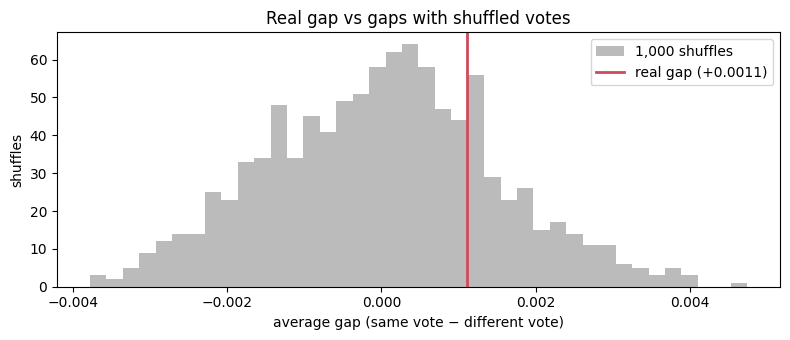

In [29]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(shuffled, bins=40, color='#bbbbbb', label='1,000 shuffles')
ax.axvline(real.mean(), color='#d1495b', lw=2, label=f'real gap ({real.mean():+.4f})')
ax.set_xlabel('average gap (same vote − different vote)'); ax.set_ylabel('shuffles'); ax.legend()
ax.set_title('Real gap vs gaps with shuffled votes'); plt.tight_layout(); plt.show()

### 4d. Niðurstøða (conclusion)

Inside the same debate, members who voted the **same** do **not** use measurably more similar words than members who voted **differently**: the average gap is **+0.0011**, and about 1 in 4 shuffles of the votes give a gap at least as big (p ≈ 0.2).

So with TF-IDF and cosine **we cannot see the vote in the words**. That does not prove members don't vote the way they speak: TF-IDF mostly sees **what** they talk about, not **for or against** (see Ruth Vang in 3c).

## Step 5: Step 4 again, with 300+ word texts only

Short texts have few words, so their cosine is noisy and may hide a real gap.

In [30]:
def gap_test(D, keep, n_shuffles=1000, seed=1):
    """Step 4 on document vectors D, only rows where keep is True:
    real average gap, and p = share of vote-shuffles with a gap at least as big."""
    vote = fi['vote'].to_numpy()
    use = {}                                                           # debate -> (rows, pair similarities, pair index)
    for case, pos in fi[keep].groupby('case_number').indices.items():
        rows_ = fi[keep].index[pos]
        v = vote[rows_]
        if (v == 'Fyri').sum() >= 2 and (v == 'Ímóti').sum() >= 2:
            iu = np.triu_indices(len(rows_), 1)
            use[case] = (rows_, cosine_similarity(D[rows_])[iu], iu)

    def mean_gap(vote):
        gaps = []
        for rows_, s, iu in use.values():
            v = vote[rows_]
            same_pair = (v[:, None] == v[None, :])[iu]
            gaps.append(s[same_pair].mean() - s[~same_pair].mean())
        return np.mean(gaps)

    real_gap = mean_gap(vote)
    rng = np.random.default_rng(seed)
    null = []
    for _ in range(n_shuffles):
        v = vote.copy()
        for rows_, _s, _iu in use.values():
            v[rows_] = rng.permutation(v[rows_])
        null.append(mean_gap(v))
    null = np.array(null)
    return {'documents': int(keep.sum()), 'debates': len(use), 'gap': round(real_gap, 4),
            'p (vs shuffled)': round((null >= real_gap).mean(), 3)}, null

all_rows  = np.ones(len(fi), dtype=bool)
long_rows = fi['words'].to_numpy() >= 300
res_all, null_all = gap_test(X, all_rows)
res_long, null_long = gap_test(X, long_rows)
step5 = pd.DataFrame([{'texts': 'all', **res_all}, {'texts': 'at least 300 words', **res_long}])
step5.style.hide(axis='index').format({'gap': '{:+.4f}', 'p (vs shuffled)': '{:.2f}'})

texts,documents,debates,gap,p (vs shuffled)
all,3091,133,+0.0011,0.20
at least 300 words,2220,122,+0.0019,0.11


**What is p?** We shuffle the votes inside each debate 1,000 times (votes then mean nothing) and compute the gap each time: the grey bars below. **p** = the share of shuffles with a gap **at least as big** as the real one (the red line). Small p (below 0.05) = the real gap is rarely reached by chance.

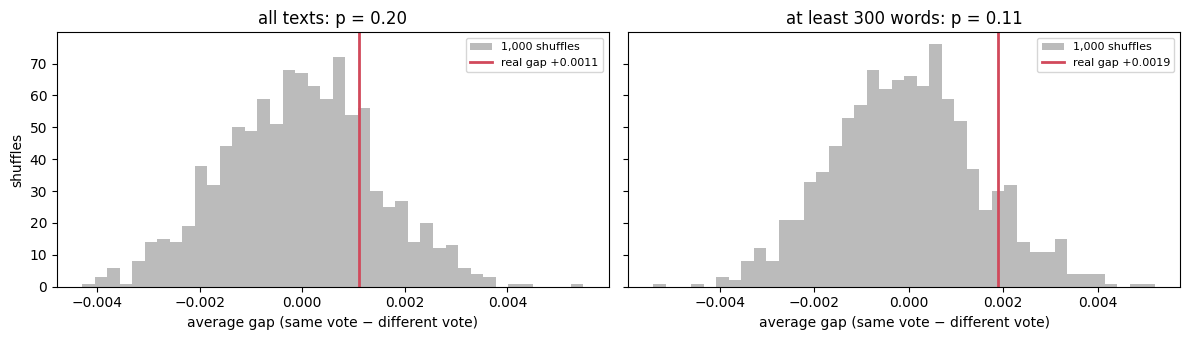

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, null, res, title in ((axes[0], null_all, res_all, 'all texts'),
                             (axes[1], null_long, res_long, 'at least 300 words')):
    ax.hist(null, bins=40, color='#bbbbbb', label='1,000 shuffles')
    ax.axvline(res['gap'], color='#d1495b', lw=2, label=f"real gap {res['gap']:+.4f}")
    ax.set_title(f"{title}: p = {res['p (vs shuffled)']:.2f}")
    ax.set_xlabel('average gap (same vote − different vote)'); ax.legend(fontsize=8)
axes[0].set_ylabel('shuffles')
plt.tight_layout(); plt.show()

### 5. Niðurstøða

With only the longer texts the gap gets a bit **bigger** (+0.0019 instead of +0.0011) and p gets **smaller** (about 0.11 instead of 0.2), so short, noisy texts did hide a little. But it is **still not clearly above chance**: about 1 in 9 shuffles give a gap at least this big. The answer stays the same: with TF-IDF and cosine we cannot clearly see the vote in the words.

*(The "all" row gives p = 0.21 here and 0.23 in 4c: both use 1,000 random shuffles, so p moves a little between runs.)*

## Step 6: PPMI (week 6)

TF-IDF only matches **exactly the same word**: *arbeiðsvikuna* and *arbeiðsvikan*, or *dýrari* and *kostar meira*, count as unrelated. **PPMI** describes each word by **the words around it**, so words used in the same way get similar vectors.

**Plan:**
- **6a.** Build PPMI word vectors from **all** cleaned speech (also speeches without a vote: PPMI only needs text). Names removed.
- **6b.** Check: the closest words of a few words.
- **6c.** Turn each text into a vector (like the Marvel map in week 6: the average of its words' vectors, weighted by TF-IDF) and do Step 4 again.

### 6a. PPMI word vectors

1. Split every speech segment into words. Keep words used at least **20 times**.
2. **Count** for every word which words appear within **4 words** left or right → the word × context table.
3. **PMI** = log( how often the pair appears together / how often it would by chance ). Keep only **positive** values → **PPMI**.
4. A word's **PPMI vector** = its row in that table.

(Standard trick: context counts are raised to the power 0.75, so very rare context words don't get huge values.)

In [32]:
from collections import Counter
from scipy import sparse
from sklearn.preprocessing import normalize

TOKEN = re.compile(r'[^\W\d_]+')
name_set = set(name_words)
sents = [[w for w in TOKEN.findall(t.lower()) if w not in name_set] for t in clean_speech['text']]
counts = Counter(w for s in sents for w in s)
ppmi_vocab = np.array(sorted(w for w, c in counts.items() if c >= 20))
ppmi_index = {w: i for i, w in enumerate(ppmi_vocab)}

pairs_r, pairs_c = [], []
for s in sents:
    ids = np.array([ppmi_index.get(w, -1) for w in s])
    for k in range(1, 5):                                     # words 1, 2, 3, 4 apart
        a, b = ids[:-k], ids[k:]
        ok_ = (a >= 0) & (b >= 0)
        pairs_r.append(a[ok_]); pairs_c.append(b[ok_])
r, c = np.concatenate(pairs_r), np.concatenate(pairs_c)
V = len(ppmi_vocab)
counts_table = sparse.coo_matrix((np.ones(len(r)), (r, c)), shape=(V, V)).tocsr()
counts_table = (counts_table + counts_table.T).tocoo()         # left and right neighbours

total = counts_table.sum()
p_word = np.asarray(counts_table.sum(axis=1)).ravel() / total
p_ctx = np.asarray(counts_table.sum(axis=0)).ravel() ** 0.75
p_ctx = p_ctx / p_ctx.sum()
pmi = np.log((counts_table.data / total) / (p_word[counts_table.row] * p_ctx[counts_table.col]))
positive = pmi > 0
PPMI = normalize(sparse.csr_matrix((pmi[positive], (counts_table.row[positive], counts_table.col[positive])), shape=(V, V)))
print(f'{sum(counts.values()):,} words spoken | {V:,} words used at least 20 times -> PPMI table {V:,} x {V:,}')

7,015,570 words spoken | 11,407 words used at least 20 times -> PPMI table 11,407 x 11,407


**A look inside the PPMI table:** one row per **word**, one column per **nearby word**. Each cell = **PPMI**: the PMI (how much more often than chance the two words appear within 4 words of each other), with values below 0 set to **0**. Compare with the TF-IDF table in 3d, where the rows are **texts**.

In [33]:
PPMI_raw = sparse.csr_matrix((pmi[positive], (counts_table.row[positive], counts_table.col[positive])), shape=(V, V))
print(f'{V:,} rows (words) x {V:,} columns (nearby words) | {PPMI_raw.nnz / V**2:.1%} of the cells are not 0')
show_rows = ['arbeiðsvikuna', 'familjulív', 'arbeiðslív', 'dýrari', 'bíligari', 'krónur']
show_cols = ['stytta', 'tímar', 'arbeiðslív', 'familjulív', 'javnvág', 'krónur', 'milliónir', 'fiskidagar']
pd.DataFrame(PPMI_raw[[ppmi_index[w] for w in show_rows]][:, [ppmi_index[w] for w in show_cols]].toarray().round(1),
             index=show_rows, columns=show_cols)

11,407 rows (words) x 11,407 columns (nearby words) | 2.3% of the cells are not 0


,stytta,tímar,arbeiðslív,familjulív,javnvág,krónur,milliónir,fiskidagar
arbeiðsvikuna,6.8,3.8,2.8,2.9,0.0,0.0,0.0,0.0
familjulív,3.4,2.4,7.8,5.3,4.6,0.0,0.0,0.0
arbeiðslív,0.0,2.4,0.0,7.8,4.6,0.0,0.0,0.0
dýrari,0.0,0.0,0.0,0.0,0.0,0.8,1.7,0.0
bíligari,0.0,0.0,0.0,0.0,0.0,0.4,0.0,0.0
krónur,0.0,0.0,0.0,0.0,0.0,1.8,3.6,0.0


### 6b. Check: the closest words (cosine between PPMI vectors)

In [34]:
def neighbours(word, k=8):
    i = ppmi_index[word]
    s = (PPMI @ PPMI[i].T).toarray().ravel()
    s[i] = -1
    return ', '.join(f'{ppmi_vocab[j]} ({s[j]:.2f})' for j in np.argsort(-s)[:k])

check = ['landsstýrið', 'arbeiðsvikuna', 'familjulív', 'dýrari', 'jalig', 'krónur']
pd.DataFrame({'word': check, 'closest words': [neighbours(w) for w in check]}).style.hide(axis='index')

word,closest words
landsstýrið,"løgtingið (0.28), landsstýri (0.26), landsstýrismaðurin (0.22), samgongan (0.20), landstýrið (0.20), heitir (0.17), landsstýrinum (0.17), mann (0.17)"
arbeiðsvikuna,"stytta (0.56), arbeiðstíðina (0.25), stytt (0.25), sjeyogtretivu (0.21), tímum (0.21), tímatalið (0.21), arbeiðsviku (0.20), arbeiðsvikan (0.20)"
familjulív,"arbeiðslív (0.41), arbeiðsmarknað (0.21), samanhang (0.16), hanga (0.15), fáa (0.15), javnrættindi (0.14), arbeiðs (0.13), sálarheilsu (0.13)"
dýrari,"bíligari (0.23), dýrt (0.18), dýrar (0.18), truplari (0.16), enn (0.16), bilar (0.15), hægri (0.15), munandi (0.14)"
jalig,"positiv (0.24), jaligur (0.21), jalið (0.18), skeptisk (0.17), kritisk (0.17), sum (0.17), jaliga (0.16), positivt (0.15)"
krónur,"milliónir (0.68), hundrað (0.66), túsund (0.57), komma (0.50), miliónir (0.46), fimm (0.45), krónum (0.45), umleið (0.44)"


- **Other forms and spellings land together** (e.g. *landsstýrið* → *landsstýri, landsstýrinum*, and *landstýrið*, a speech-to-text spelling). That is what TF-IDF cannot do.
- **⚠️ Opposites land together too** (*dýrari* → *bíligari*; *jalig* → *skeptisk, kritisk*): they are used in the same places. So PPMI closeness means **"used in the same way"**, not "same opinion".

### 6c. Texts as PPMI vectors, and Step 4 again

Each text's vector = the **average of its words' PPMI vectors, weighted by their TF-IDF score** (the same recipe as the Marvel map in week 6).

Averages of word vectors all look alike (they share the common words' contexts), so we also try a **centred** version: subtract the average text, so only what is special about each text is left.

<div style="background-color:rgba(201,185,138,0.15); border-left:5px solid #c9b98a; padding:10px 14px;">

**Example** (made up: a text of 3 words, vectors of 3 numbers). Edva's text = *tímar, løn, náttarvakt*

| word | PPMI vector (near *arbeiði*, *pengar*, *familja*) | TF-IDF weight | weight × vector |
|---|---|---|---|
| tímar | (6, 1, 2) | 0.6 | (3.6, 0.6, 1.2) |
| løn | (2, 7, 0) | 0.3 | (0.6, 2.1, 0) |
| náttarvakt | (5, 1, 1) | 0.1 | (0.5, 0.1, 0.1) |
| **text vector** (sum) | | | **(4.7, 2.8, 1.3)** |

→ mostly "near *arbeiði*", because the most important word (*tímar*) sits there. 🥤 Like a smoothie: the fruit you use most decides the taste. Marvel: Spider-Man = a mix of *web, spider, venom*.

</div>

average cosine between two texts: PPMI 0.80 | PPMI centred 0.01 | TF-IDF 0.04


vectors,documents,debates,gap,p (vs shuffled)
TF-IDF (Step 4),3091,133,+0.0011,0.20
PPMI,3091,133,-0.0010,0.65
"PPMI, centred",3091,133,-0.0122,0.85


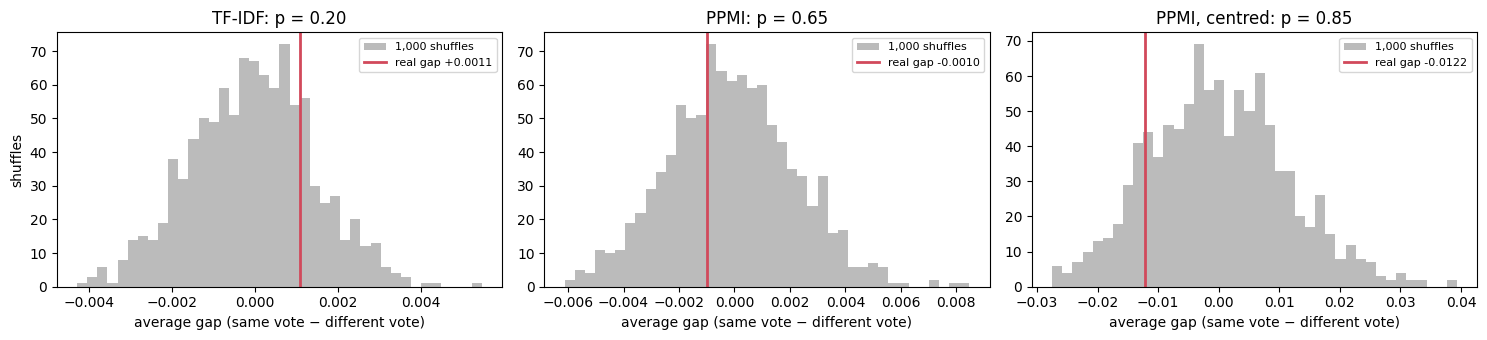

In [35]:
tfidf_index = {w: i for i, w in enumerate(words)}
common = [w for w in ppmi_vocab if w in tfidf_index]               # words in both tables
D = (X[:, [tfidf_index[w] for w in common]] @ PPMI[[ppmi_index[w] for w in common]]).tocsr()
D_centred = D.toarray()
D_centred -= D_centred.mean(axis=0)

sample = np.triu_indices(300, 1)
print(f'average cosine between two texts: PPMI {cosine_similarity(D[:300])[sample].mean():.2f} | '
      f'PPMI centred {cosine_similarity(D_centred[:300])[sample].mean():.2f} | TF-IDF {cosine_similarity(X[:300])[sample].mean():.2f}')

res6_ppmi, null6_ppmi = gap_test(D, all_rows)
res6_cent, null6_cent = gap_test(D_centred, all_rows)
step6 = pd.DataFrame([{'vectors': 'TF-IDF (Step 4)', **res_all},
                      {'vectors': 'PPMI', **res6_ppmi},
                      {'vectors': 'PPMI, centred', **res6_cent}])
display(step6.style.hide(axis='index').format({'gap': '{:+.4f}', 'p (vs shuffled)': '{:.2f}'}))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, null, res, title in ((axes[0], null_all, res_all, 'TF-IDF'),
                             (axes[1], null6_ppmi, res6_ppmi, 'PPMI'),
                             (axes[2], null6_cent, res6_cent, 'PPMI, centred')):
    ax.hist(null, bins=40, color='#bbbbbb', label='1,000 shuffles')
    ax.axvline(res['gap'], color='#d1495b', lw=2, label=f"real gap {res['gap']:+.4f}")
    ax.set_title(f"{title}: p = {res['p (vs shuffled)']:.2f}")
    ax.set_xlabel('average gap (same vote − different vote)'); ax.legend(fontsize=8)
axes[0].set_ylabel('shuffles')
plt.tight_layout(); plt.show()

### 6d. Remove the most common words as neighbours

Almost every word has *og, tað, at, sum, í* … as neighbours (in 90%+ of the rows of the PPMI table). Maybe those shared columns make all texts look alike. Test: remove the **100 most common words as neighbours** (columns), and do 6c again. (The arrow version is in Step 7.)

In [36]:
top100 = [w for w, _ in counts.most_common(100)]
keep_col = np.ones(V)
keep_col[[ppmi_index[w] for w in top100 if w in ppmi_index]] = 0
PPMI_nostop = normalize(PPMI_raw @ sparse.diags(keep_col))          # same table, those 100 columns set to 0
D_nostop = (X[:, [tfidf_index[w] for w in common]] @ PPMI_nostop[[ppmi_index[w] for w in common]]).tocsr()

print(f'average cosine between two texts: {cosine_similarity(D_nostop[:300])[sample].mean():.2f}  (before: 0.80)')
pd.DataFrame([{'vectors': 'PPMI (6c)', **res6_ppmi},
              {'vectors': 'PPMI, without the 100 most common neighbours', **gap_test(D_nostop, all_rows)[0]}]
             ).style.hide(axis='index').format({'gap': '{:+.4f}', 'p (vs shuffled)': '{:.2f}'})

average cosine between two texts: 0.76  (before: 0.80)


vectors,documents,debates,gap,p (vs shuffled)
PPMI (6c),3091,133,-0.0010,0.65
"PPMI, without the 100 most common neighbours",3091,133,-0.0012,0.67


### 6. Niðurstøða

**With pairs (the Step 4 test), PPMI does not show the vote either.** The gap is about **0 or even below**, and most shuffles give a gap at least as big.

**Why pairs don't work with PPMI:**
- Averaging word vectors makes all texts look very alike (average cosine about 0.8), so small differences drown. Removing the most common neighbours (6d) hardly changes this: a text has hundreds of words, and their average is mostly "general Løgting language".
- PPMI puts opposites close together (*dýrari ~ bíligari*), so "for" and "against" words look the same.

**But see Step 7:** with the arrow, PPMI **does** show the vote. PPMI is also useful for **words** (6b): it finds forms, spellings and related words.

## Step 7: a Fyri ↔ Ímóti arrow (like the map in week 6)

*Steps 4-6 asked whether members on the same side **sound alike** (pairs), and the answer was no. Step 7 asks a different, weaker question with the same TF-IDF table: does each text **lean towards its own side**?*

In week 6, the arrow **magic − science** gave each character a score on a science ↔ magic scale. We do the same with the two sides of a vote.

**Inside each debate, for each member:**
1. **Fyri point** = the average TF-IDF row of the Fyri speakers in the debate, **without the member we are scoring**. **Ímóti point** = the same for the Ímóti speakers.
2. **Arrow** = Fyri point − Ímóti point.
3. **Score** = arrow · the member's own row (dot product). Above 0 → the text leans **Fyri**, below 0 → leans **Ímóti**.

**Normalised:** the Fyri point and the Ímóti point are both scaled to the **same size** before comparing, so only their **direction** counts (which words, in what mix). Why: when one side uses the same words, its average is "big"; when the other side argues in different ways, its average is "small". Without scaling, the big one would pull **everyone** towards it, like a louder voice.

**Pairs (Step 4) vs arrow:** Step 4 asked whether a side *sounds alike*. The arrow only asks whether each text **leans towards its own side** — a side can do that even if its members argue in different ways.

<div style="background-color:rgba(201,185,138,0.15); border-left:5px solid #c9b98a; padding:10px 14px;">

**Example: "the other"**, scoring Ruth Vang (Ímóti) in the work-week debate

| | built from | Ruth included? |
|---|---|---|
| Fyri point | the 9 Fyri speakers | – |
| Ímóti point | the **other 10** Ímóti speakers | ❌ left out |

→ Otherwise her own text would help build the Ímóti point, and she would land there automatically. The arrow is rebuilt for every member.

</div>

In [37]:
def arrow_scores(G, v):
    """Leave-one-out arrow scores in one debate. G = dot products between all texts, v = votes.
    Each side's centre (the OTHER members on that side) is normalised to length 1, so only its direction counts."""
    F = (v == 'Fyri')
    d = np.diag(G)
    out = 0
    for side, sign in ((F, 1), (~F, -1)):
        row = G[:, side].sum(axis=1)
        num = row - d * side                                              # dot product with the others' summed vector
        den = np.sqrt(G[np.ix_(side, side)].sum() - side * (2 * row - d))   # length of the others' summed vector
        out = out + sign * num / den                                      # = cosine with the others' centre
    return out

def auc(s, fyri):
    """Share of (Fyri text, Ímóti text) pairs where the Fyri text has the higher score (ties count half)."""
    f, i = s[fyri][:, None], s[~fyri][None, :]
    return (f > i).mean() + 0.5 * (f == i).mean()

def arrow_test(D, keep, n_shuffles=1000, seed=1):
    vote = fi['vote'].to_numpy()
    use = []
    for case, pos in fi[keep].groupby('case_number').indices.items():
        rows_ = fi[keep].index[pos]
        v = vote[rows_]
        if (v == 'Fyri').sum() >= 2 and (v == 'Ímóti').sum() >= 2:
            Dr = D[rows_]
            G = Dr @ Dr.T
            use.append((rows_, G.toarray() if hasattr(G, 'toarray') else G))

    def share_and_auc(vote):
        right, aucs = [], []
        for rows_, G in use:
            v = vote[rows_]
            s = arrow_scores(G, v)
            right.append((s > 0) == (v == 'Fyri'))
            aucs.append(auc(s, v == 'Fyri'))          # AUC inside this debate
        return np.concatenate(right).mean(), np.mean(aucs)

    real_share, real_auc = share_and_auc(vote)
    rng = np.random.default_rng(seed)
    null, null_auc = [], []
    for _ in range(n_shuffles):
        v = vote.copy()
        for rows_, _G in use:
            v[rows_] = rng.permutation(v[rows_])
        sh, au = share_and_auc(v)
        null.append(sh); null_auc.append(au)
    null, null_auc = np.array(null), np.array(null_auc)
    return {'texts': sum(len(r) for r, _ in use), 'debates': len(use),
            'on own side': round(real_share, 3), 'shuffled (average)': round(null.mean(), 3),
            'p (vs shuffled)': round((null >= real_share).mean(), 3),
            'AUC': round(real_auc, 3), 'AUC shuffled': round(null_auc.mean(), 3),
            'p (AUC)': round((null_auc >= real_auc).mean(), 3)}, null, null_auc

### 7a. One debate: the shorter work week

Each member's score on the Fyri ↔ Ímóti arrow (built from the others).

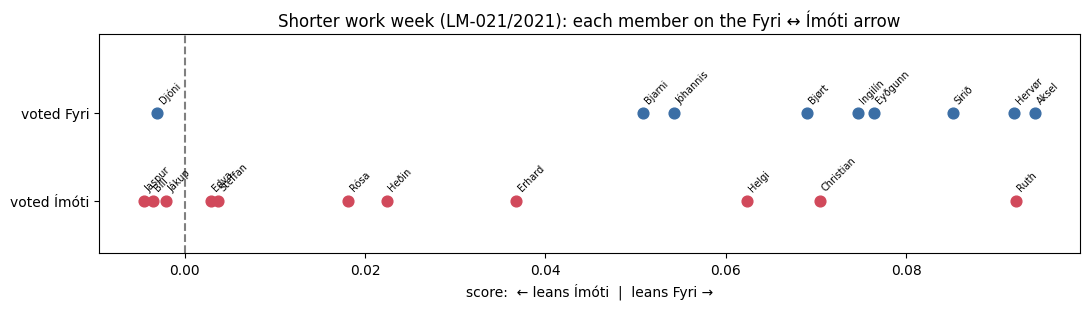

on their own side: 55% of 20 members


In [38]:
one = fi[fi['case_number'] == 'LM-021/2021']
G1 = (X[one.index] @ X[one.index].T).toarray()
sc = arrow_scores(G1, one['vote'].to_numpy())

fig, ax = plt.subplots(figsize=(11, 3.2))
for k, (side, col) in enumerate((('Ímóti', '#d1495b'), ('Fyri', '#3b6ea5'))):
    m = (one['vote'] == side).to_numpy()
    ax.scatter(sc[m], np.full(m.sum(), k), color=col, s=60, label=side)
    for x_, n_ in zip(sc[m], one['name'][m]):
        ax.annotate(n_.split()[0], (x_, k), xytext=(0, 7), textcoords='offset points', fontsize=7, rotation=45)
ax.axvline(0, color='grey', ls='--')
ax.set_yticks([0, 1]); ax.set_yticklabels(['voted Ímóti', 'voted Fyri']); ax.set_ylim(-0.6, 1.9)
ax.set_xlabel('score:  ← leans Ímóti  |  leans Fyri →')
ax.set_title('Shorter work week (LM-021/2021): each member on the Fyri ↔ Ímóti arrow')
plt.tight_layout(); plt.show()
print(f"on their own side: {((sc > 0) == (one['vote'] == 'Fyri').to_numpy()).mean():.0%} of {len(one)} members")

### 7b. Every text in all debates

The same plot as 7a, but with **all 133 debates** together (one dot = one text). Right of 0 = leans Fyri, left of 0 = leans Ímóti.
Blue dots right and red dots left are "on own side".

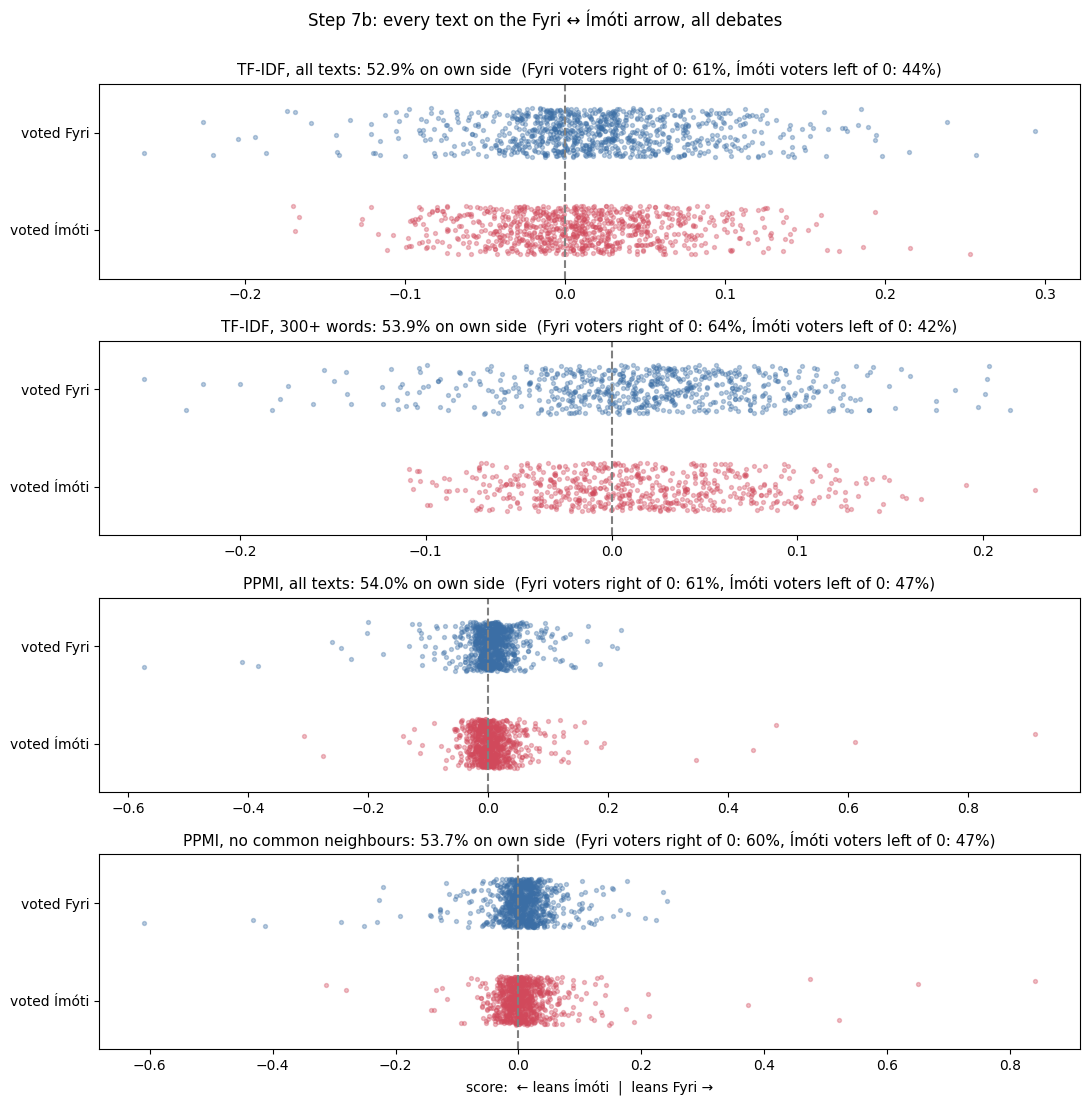

In [39]:
def all_scores(D, keep):
    """Arrow score of every text in every debate with at least 2 texts on each side (same as arrow_test)."""
    vote = fi['vote'].to_numpy()
    out_s, out_v = [], []
    for case, pos in fi[keep].groupby('case_number').indices.items():
        rows_ = fi[keep].index[pos]
        v = vote[rows_]
        if (v == 'Fyri').sum() >= 2 and (v == 'Ímóti').sum() >= 2:
            Dr = D[rows_]
            G = Dr @ Dr.T
            G = G.toarray() if hasattr(G, 'toarray') else G
            out_s.append(arrow_scores(G, v)); out_v.append(v)
    return np.concatenate(out_s), np.concatenate(out_v)

rng_plot = np.random.default_rng(0)
fig, axes = plt.subplots(4, 1, figsize=(11, 11))
for ax, (title, Dm, keep) in zip(axes, [('TF-IDF, all texts', X, all_rows), ('TF-IDF, 300+ words', X, long_rows),
                                        ('PPMI, all texts', D, all_rows), ('PPMI, no common neighbours', D_nostop, all_rows)]):
    s, v = all_scores(Dm, keep)
    for k, (side, col) in enumerate((('Ímóti', '#d1495b'), ('Fyri', '#3b6ea5'))):
        m = v == side
        ax.scatter(s[m], k + rng_plot.uniform(-0.25, 0.25, m.sum()), color=col, s=8, alpha=0.35)
    ax.axvline(0, color='grey', ls='--')
    ax.set_yticks([0, 1]); ax.set_yticklabels(['voted Ímóti', 'voted Fyri']); ax.set_ylim(-0.5, 1.5)
    fyri_ok = (s[v == 'Fyri'] > 0).mean(); imoti_ok = (s[v == 'Ímóti'] < 0).mean()
    ax.set_title(f"{title}: {((s > 0) == (v == 'Fyri')).mean():.1%} on own side  "
                 f"(Fyri voters right of 0: {fyri_ok:.0%}, Ímóti voters left of 0: {imoti_ok:.0%})", fontsize=11)
axes[-1].set_xlabel('score:  ← leans Ímóti  |  leans Fyri →')
fig.suptitle('Step 7b: every text on the Fyri ↔ Ímóti arrow, all debates', y=1.0)
plt.tight_layout(); plt.show()

### 7c. All debates, and against chance

**On own side** = share of texts whose score points to the side the member actually voted. Chance is **not exactly 50%** (leaving a member out shifts the arrow a little), so we compare with **shuffled votes** (1,000 times).

**AUC** = pick one Fyri text and one Ímóti text from the same debate: how often does the Fyri text have the higher score? 1 = perfect.
It does **not** use the 0 line, so the tilt seen in 7b doesn't matter. Computed inside each debate, then averaged over the debates.

**Careful: chance here is not 0.5 but about 0.32.** Leaving each member out of their own side ("the other") pushes every text a little towards the **other** side: Fyri texts score a bit lower, Ímóti texts a bit higher. That flips many Fyri–Ímóti pairs, so even random votes give an AUC below 0.5 (most in small debates). That is why we compare with the **shuffles**, not with 0.5.

vectors,texts used,texts,debates,on own side,shuffled (average),p (vs shuffled),AUC,AUC shuffled,p (AUC)
TF-IDF,all,1692,133,52.9%,49.9%,0.007,0.398,0.321,0.000
TF-IDF,at least 300 words,1212,122,53.9%,48.7%,0.000,0.330,0.226,0.000
PPMI,all,1692,133,54.0%,49.7%,0.000,0.391,0.328,0.001
"PPMI, no common neighbours (6d)",all,1692,133,53.7%,49.8%,0.000,0.392,0.326,0.000


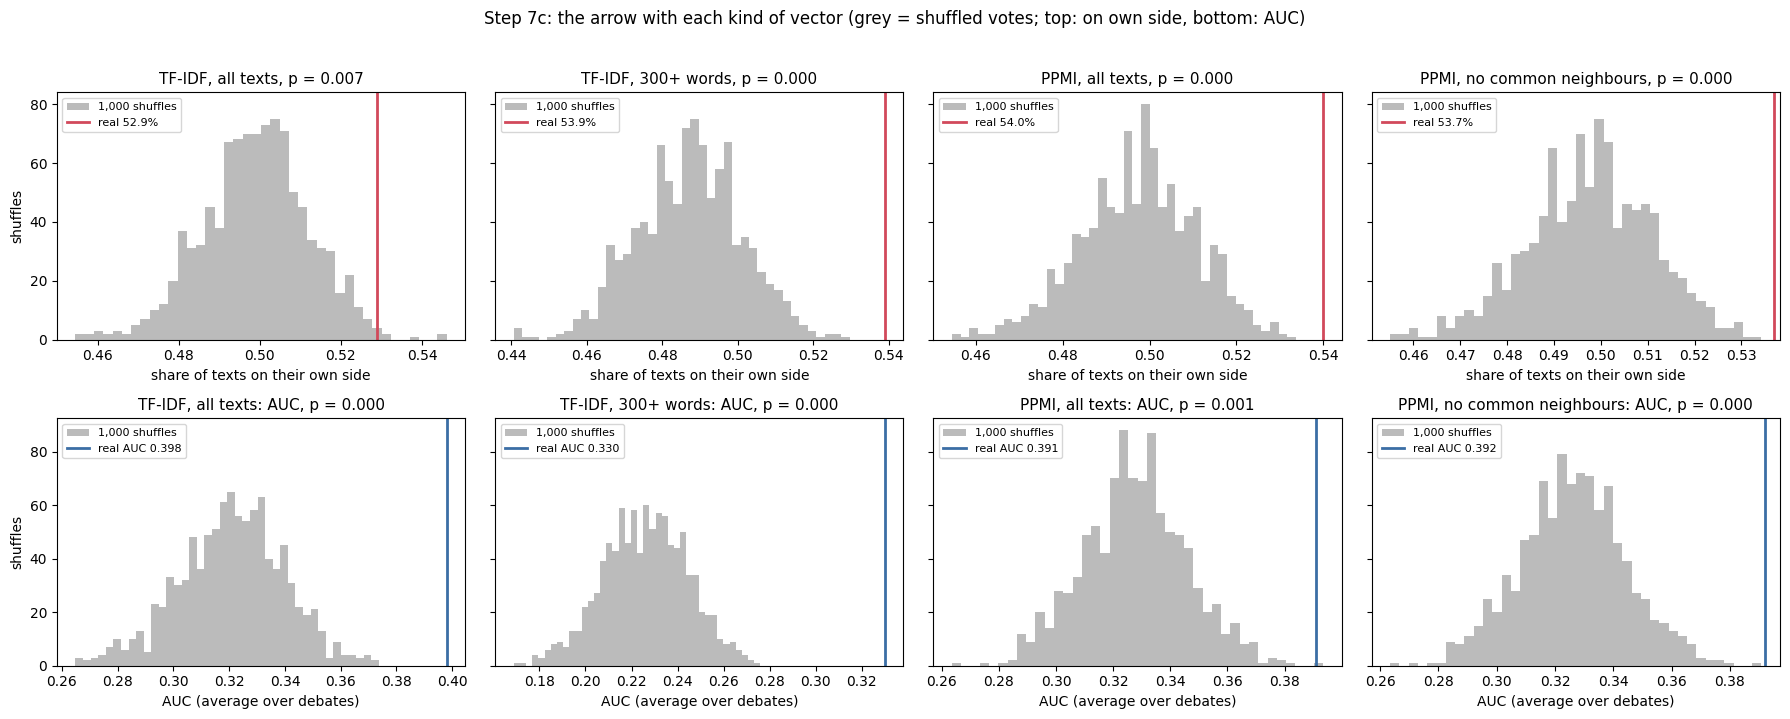

In [40]:
res7_all, null7_all, auc7_all = arrow_test(X, all_rows)
res7_long, null7_long, auc7_long = arrow_test(X, long_rows)
res7_ppmi, null7_ppmi, auc7_ppmi = arrow_test(D, all_rows)
res7_nostop, null7_nostop, auc7_nostop = arrow_test(D_nostop, all_rows)
step7 = pd.DataFrame([{'vectors': 'TF-IDF', 'texts used': 'all', **res7_all},
                      {'vectors': 'TF-IDF', 'texts used': 'at least 300 words', **res7_long},
                      {'vectors': 'PPMI', 'texts used': 'all', **res7_ppmi},
                      {'vectors': 'PPMI, no common neighbours (6d)', 'texts used': 'all', **res7_nostop}])
display(step7.style.hide(axis='index').format({'on own side': '{:.1%}', 'shuffled (average)': '{:.1%}', 'p (vs shuffled)': '{:.3f}', 'AUC': '{:.3f}', 'AUC shuffled': '{:.3f}', 'p (AUC)': '{:.3f}'}))

panels = [('TF-IDF, all texts', res7_all, null7_all, auc7_all), ('TF-IDF, 300+ words', res7_long, null7_long, auc7_long),
          ('PPMI, all texts', res7_ppmi, null7_ppmi, auc7_ppmi), ('PPMI, no common neighbours', res7_nostop, null7_nostop, auc7_nostop)]
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey='row')
for col, (title, res, null, null_auc) in enumerate(panels):
    ax = axes[0, col]
    ax.hist(null, bins=40, color='#bbbbbb', label='1,000 shuffles')
    ax.axvline(res['on own side'], color='#d1495b', lw=2, label=f"real {res['on own side']:.1%}")
    ax.set_title(f"{title}, p = {res['p (vs shuffled)']:.3f}", fontsize=11)
    ax.set_xlabel('share of texts on their own side'); ax.legend(fontsize=8)
    ax = axes[1, col]
    ax.hist(null_auc, bins=40, color='#bbbbbb', label='1,000 shuffles')
    ax.axvline(res['AUC'], color='#3b6ea5', lw=2, label=f"real AUC {res['AUC']:.3f}")
    ax.set_title(f"{title}: AUC, p = {res['p (AUC)']:.3f}", fontsize=11)
    ax.set_xlabel('AUC (average over debates)'); ax.legend(fontsize=8)
axes[0, 0].set_ylabel('shuffles'); axes[1, 0].set_ylabel('shuffles')
fig.suptitle('Step 7c: the arrow with each kind of vector (grey = shuffled votes; top: on own side, bottom: AUC)', y=1.02)
plt.tight_layout(); plt.show()

### 7. Niðurstøða

**With the arrow we see a small but real signal, with every kind of vector:**

| vectors | texts | on own side | shuffled | p |
|---|---|---|---|---|
| TF-IDF | all | 52.9% | 49.9% | ≈ 0.01 |
| TF-IDF | 300+ words | 53.9% | 48.7% | < 0.001 |
| PPMI | all | 54.0% | 49.7% | < 0.001 |

**How to read it:** the lean is **weak**: about 3-5 texts in 100 more than chance. Single debates often don't show it. But across 133 debates, texts do lean towards their own side. Longer texts show it more clearly (less noise), and PPMI shows it as clearly as TF-IDF.

**The normalising mattered:** with the old, un-normalised arrow, PPMI looked like chance (47%), because a side that sounds alike pulled everyone towards it.

**Why the arrow finds it and pairs (Steps 4-6) did not:** a side does not have to *sound alike* to *lean the same way*.

**To check next:** the lean could come from the **party or bloc** (government vs opposition) rather than the vote itself → Step 8.

## Step 8: is it the vote, or government vs opposition?

The 53% in Step 7 could just mean that a text **sounds like a government or an opposition member**: the vote and the bloc are often the same (on an opposition proposal, the opposition votes Fyri and the government Ímóti).

**Government (samgonga)**, by the date of the debate:
- **before** the election (8 Dec 2022): Fólkaflokkurin, Sambandsflokkurin, Miðflokkurin
- **after**: Javnaðarflokkurin, Tjóðveldi, Framsókn
- everyone else: **opposition (andstøða)**

In [41]:
ELECTION = pd.Timestamp('2022-12-08')
GOV = {False: {'Fólkaflokkurin', 'Sambandsflokkurin', 'Miðflokkurin'},
       True:  {'Javnaðarflokkurin', 'Tjóðveldi', 'Framsókn'}}
fi['bloc'] = ['government' if party_ in GOV[d >= ELECTION] else 'opposition'
              for party_, d in zip(fi['party'], fi['date'])]
pd.crosstab(fi['bloc'], fi['vote'], margins=True, margins_name='all')

vote,Fyri,Ímóti,all
bloc,,,
government,1046,487,1533
opposition,1194,364,1558
all,2240,851,3091


### 8a. The problem: two arrows at once (the X)

Each text gets **two** scores in its debate (both built from the others, as in Step 7):
- **x:** the vote arrow, Ímóti ← → Fyri
- **y:** the bloc arrow, opposition ↓ ↑ government

**One dot = one text = everything one member said in one debate.**
- Left (one debate): one dot per member, with their name.
- Right (all debates): a member has one dot **for each debate** they spoke in.

Colour = how they voted, shape = their bloc. If the dots lie along a **diagonal**, the two arrows measure the same thing (the stork). A **round cloud** means they are separate.
Only debates with at least 2 on each side of **both** splits.

In [42]:
def loo_scores(G, pos):
    """Leave-one-out arrow scores, normalised centres (as in Step 7): cosine with the other 'pos' texts' centre
    minus cosine with the other 'not pos' texts' centre."""
    d = np.diag(G)
    out = 0
    for side, sign in ((pos, 1), (~pos, -1)):
        row = G[:, side].sum(axis=1)
        out = out + sign * (row - d * side) / np.sqrt(G[np.ix_(side, side)].sum() - side * (2 * row - d))
    return out


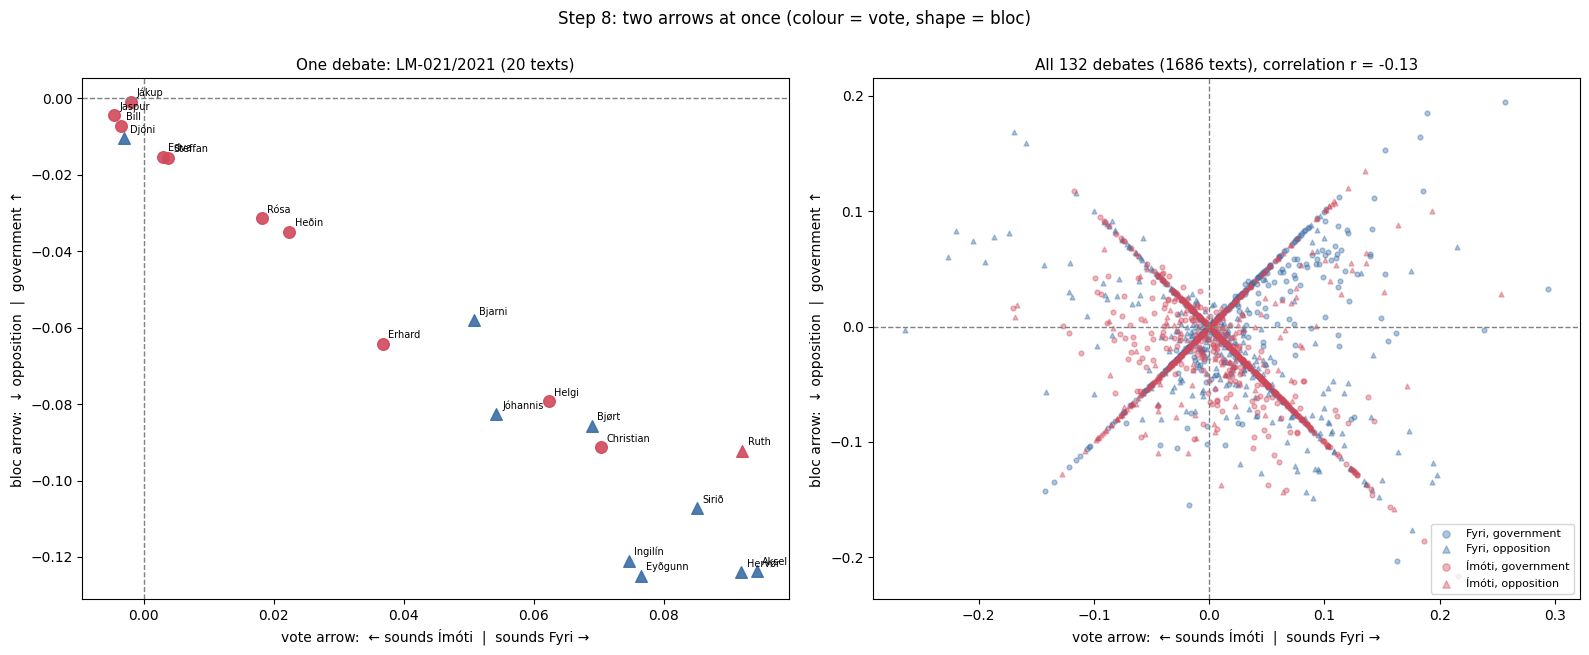

correlation between the vote arrow and the bloc arrow: r = -0.13 (1 = the same arrow, 0 = unrelated)


In [43]:
# two arrows
vote_arr, bloc_arr = fi['vote'].to_numpy(), fi['bloc'].to_numpy()
two = []
for case, pos in fi.groupby('case_number').indices.items():
    rows_ = fi.index[pos]
    F, Gv = vote_arr[rows_] == 'Fyri', bloc_arr[rows_] == 'government'
    if min(F.sum(), (~F).sum(), Gv.sum(), (~Gv).sum()) >= 2:
        G = (X[rows_] @ X[rows_].T).toarray()
        two.append((case, rows_, loo_scores(G, F), loo_scores(G, Gv)))

def draw(ax, rows_, x, y, size, alpha, names=False):
    v, b = vote_arr[rows_], bloc_arr[rows_]
    for vote_, col in (('Fyri', '#3b6ea5'), ('Ímóti', '#d1495b')):
        for bloc_, mk in (('government', 'o'), ('opposition', '^')):
            m = (v == vote_) & (b == bloc_)
            ax.scatter(x[m], y[m], color=col, marker=mk, s=size, alpha=alpha, label=f'{vote_}, {bloc_}')
    if names:
        for x_, y_, n_ in zip(x, y, fi.loc[rows_, 'name']):
            ax.annotate(n_.split()[0], (x_, y_), xytext=(4, 4), textcoords='offset points', fontsize=7)
    ax.axvline(0, color='grey', ls='--', lw=1); ax.axhline(0, color='grey', ls='--', lw=1)
    ax.set_xlabel('vote arrow:  ← sounds Ímóti  |  sounds Fyri →')
    ax.set_ylabel('bloc arrow:  ↓ opposition  |  government ↑')

ex = next((t for t in two if t[0] == 'LM-021/2021'), max(two, key=lambda t: len(t[1])))
x_all = np.concatenate([t[2] for t in two]); y_all = np.concatenate([t[3] for t in two])
rows_all = np.concatenate([t[1] for t in two])
r_all = np.corrcoef(x_all, y_all)[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
draw(axes[0], ex[1], ex[2], ex[3], 70, 0.9, names=True)
axes[0].set_title(f'One debate: {ex[0]} ({len(ex[1])} texts)', fontsize=11)
draw(axes[1], rows_all, x_all, y_all, 12, 0.4)
axes[1].set_title(f'All {len(two)} debates ({len(rows_all)} texts), correlation r = {r_all:.2f}', fontsize=11)
axes[1].legend(fontsize=8, loc='lower right', markerscale=1.5)
fig.suptitle('Step 8: two arrows at once (colour = vote, shape = bloc)', y=1.0)
plt.tight_layout(); plt.show()
print(f'correlation between the vote arrow and the bloc arrow: r = {r_all:.2f} '
      f'(1 = the same arrow, 0 = unrelated)')

**The X in the right panel:** the dots on the two lines are debates where **vote and bloc are the same split**:
- **Line going up (`/`):** all government voted Fyri and all opposition Ímóti. Then "sounds Fyri" = "sounds government", so x = y.
- **Line going down (`\`):** all opposition voted Fyri and all government Ímóti (e.g. an opposition proposal). Then x = −y.

In those debates the two arrows are **the same arrow** (the stork, made visible): vote and bloc cannot be told apart. Only the dots **off the X** (members who broke with their bloc) can separate them, and that is what 8b and the tests in 8c-8e use. (So the correlation r is not useful here: the two lines cancel out.)

### 8b. The simple fix: without the X

Take away the debates on the X (vote = bloc for **everyone**), and run the Step 7 arrow again on the debates that are left.
In these debates at least one member broke with their bloc, so vote and bloc are no longer the same split.
This is the **simple fix**. The **better fix** (8c) also splits by bloc, so vote and bloc can never be the same split.

Step 7 debates: 133 | on the X: 82 | left: 51


test,texts,debates,on own side,shuffled,p
Step 7: all debates,1692,133,52.9%,49.9%,0.007
Without the X,679,51,57.9%,56.0%,0.181


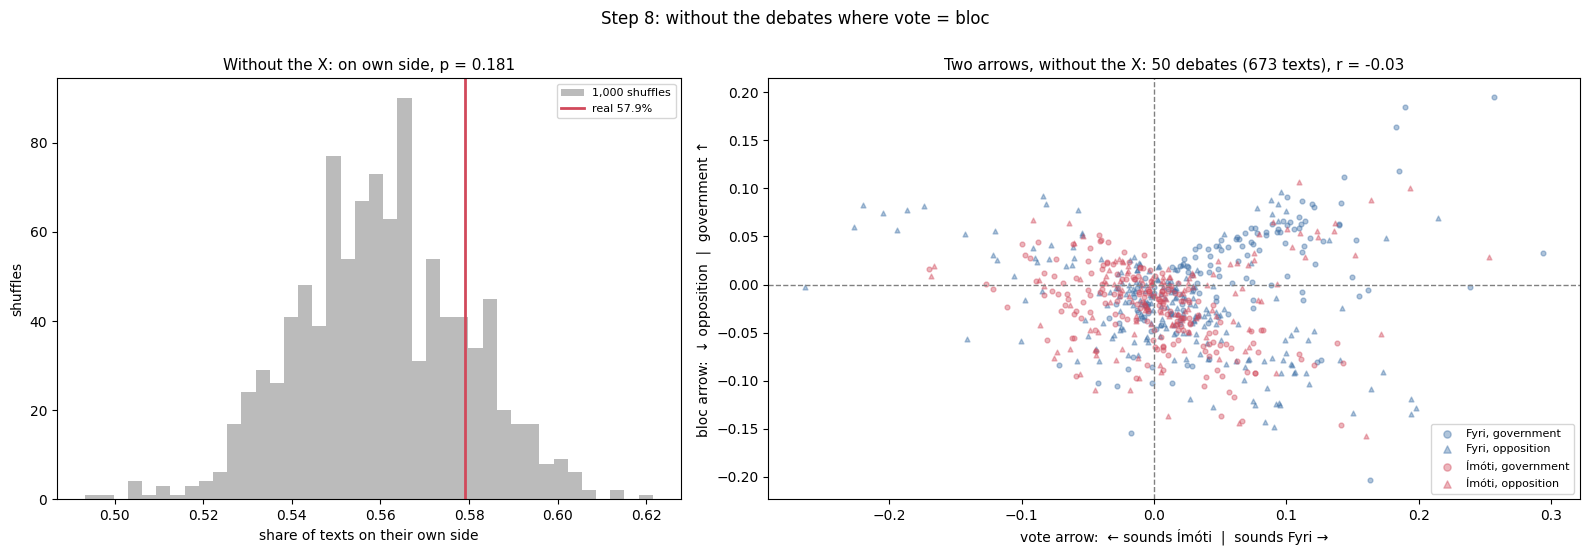

In [44]:
# without the X
pure_x = set()
for case, pos in fi.groupby('case_number').indices.items():
    rows_ = fi.index[pos]
    F, Gv = vote_arr[rows_] == 'Fyri', bloc_arr[rows_] == 'government'
    if (F == Gv).all() or (F == ~Gv).all():          # vote split = bloc split (or the mirror)
        pure_x.add(case)
no_x = ~fi['case_number'].isin(pure_x).to_numpy()
res_nox, null_nox, _ = arrow_test(X, no_x)

print(f"Step 7 debates: {res7_all['debates']} | on the X: {res7_all['debates'] - res_nox['debates']} | left: {res_nox['debates']}")
cmp = pd.DataFrame([
    {'test': 'Step 7: all debates', 'texts': res7_all['texts'], 'debates': res7_all['debates'],
     'on own side': res7_all['on own side'], 'shuffled': res7_all['shuffled (average)'], 'p': res7_all['p (vs shuffled)']},
    {'test': 'Without the X', 'texts': res_nox['texts'], 'debates': res_nox['debates'],
     'on own side': res_nox['on own side'], 'shuffled': res_nox['shuffled (average)'], 'p': res_nox['p (vs shuffled)']}])
display(cmp.style.hide(axis='index').format({'texts': '{:.0f}', 'debates': '{:.0f}', 'on own side': '{:.1%}',
                                             'shuffled': '{:.1%}', 'p': '{:.3f}'}))

left = [t for t in two if t[0] not in pure_x]
x_l = np.concatenate([t[2] for t in left]); y_l = np.concatenate([t[3] for t in left])
rows_l = np.concatenate([t[1] for t in left])
r_l = np.corrcoef(x_l, y_l)[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1, 1.3]})
axes[0].hist(null_nox, bins=40, color='#bbbbbb', label='1,000 shuffles')
axes[0].axvline(res_nox['on own side'], color='#d1495b', lw=2, label=f"real {res_nox['on own side']:.1%}")
axes[0].set_title(f"Without the X: on own side, p = {res_nox['p (vs shuffled)']:.3f}", fontsize=11)
axes[0].set_xlabel('share of texts on their own side'); axes[0].set_ylabel('shuffles'); axes[0].legend(fontsize=8)
draw(axes[1], rows_l, x_l, y_l, 12, 0.4)
axes[1].set_title(f'Two arrows, without the X: {len(left)} debates ({len(rows_l)} texts), r = {r_l:.2f}', fontsize=11)
axes[1].legend(fontsize=8, loc='lower right', markerscale=1.5)
fig.suptitle('Step 8: without the debates where vote = bloc', y=1.0)
plt.tight_layout(); plt.show()

### 8c. The better fix: the arrow from Step 7, but only inside one group

| Test | Arrow built from | Question |
|---|---|---|
| **Vote** (Step 7) | Fyri vs Ímóti, whole debate | does a text lean to its **vote**? |
| **Without the X** (see 8a, 8b) | Fyri vs Ímóti, whole debate, but only debates where **someone broke with their bloc** | does the **vote** show when vote and bloc are not the same split? |
| **A. Vote, same bloc** | Fyri vs Ímóti, only members of the **same bloc** in that debate | does the **vote** show, even without the bloc? |
| **B. Bloc, same vote** | government vs opposition, only members with the **same vote** in that debate | does the **bloc** show, even without the vote? |

Each needs at least 2 on each side in the group. Shuffles as before (1,000 times, inside each group).

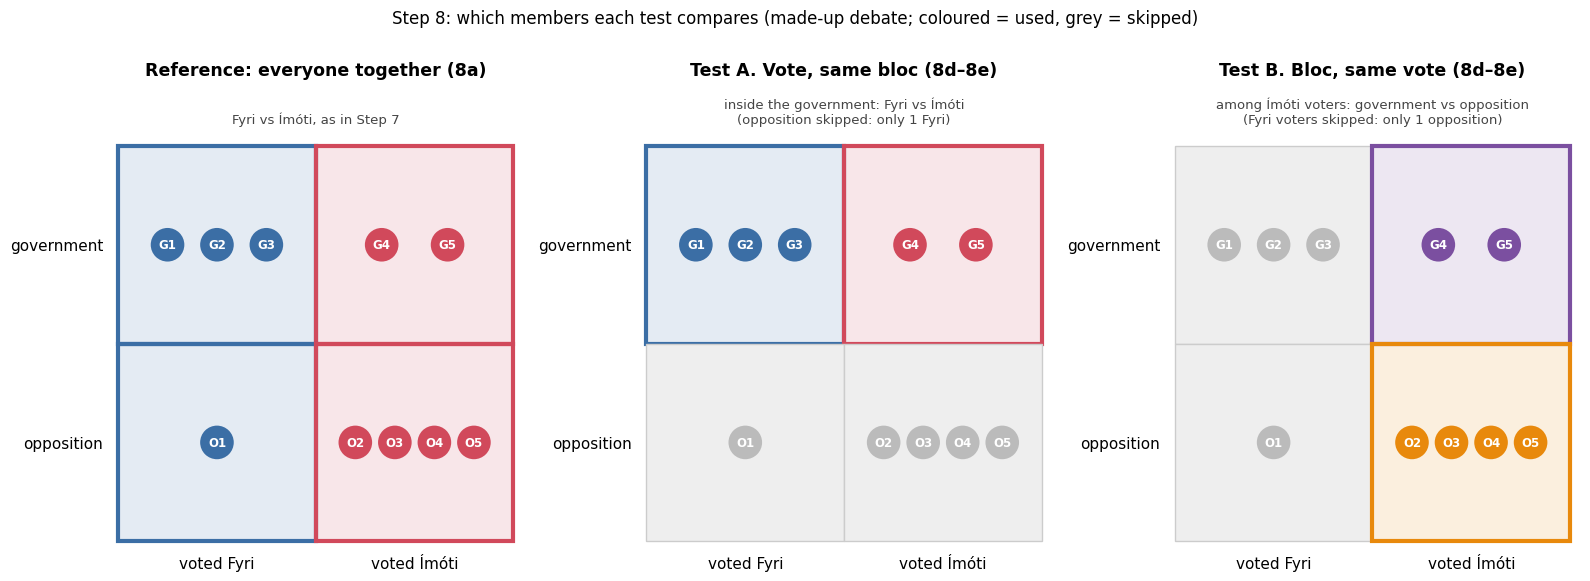

In [45]:
# Test picture: a made-up debate with 10 members (G = government, O = opposition)
from matplotlib.patches import Rectangle
people = {('government', 'Fyri'): ['G1', 'G2', 'G3'], ('government', 'Ímóti'): ['G4', 'G5'],
          ('opposition', 'Fyri'): ['O1'],             ('opposition', 'Ímóti'): ['O2', 'O3', 'O4', 'O5']}
x_people = {('government', 'Fyri'): ['G1', 'G2', 'G3', 'G4', 'G5'], ('government', 'Ímóti'): [],      # an X debate:
            ('opposition', 'Fyri'): [], ('opposition', 'Ímóti'): ['O1', 'O2', 'O3', 'O4', 'O5']}     # everyone votes with their bloc
cell_xy = {('government', 'Fyri'): (0, 1), ('government', 'Ímóti'): (1, 1),
           ('opposition', 'Fyri'): (0, 0), ('opposition', 'Ímóti'): (1, 0)}
BLUE, RED, PURPLE, ORANGE = '#3b6ea5', '#d1495b', '#7b4fa0', '#e8890c'
everyone = {('government', 'Fyri'): BLUE, ('opposition', 'Fyri'): BLUE, ('government', 'Ímóti'): RED, ('opposition', 'Ímóti'): RED}
broke = {'G4', 'G5', 'O1'}          # voted against the rest of their bloc

panels = [   # (title, explanation, members, cells used, members to ring, stamp)
    ('Reference: everyone together (8a)', 'Fyri vs Ímóti, as in Step 7', people, everyone, set(), None),
    ('Test A. Vote, same bloc (8d–8e)', 'inside the government: Fyri vs Ímóti\n(opposition skipped: only 1 Fyri)', people,
     {('government', 'Fyri'): BLUE, ('government', 'Ímóti'): RED}, set(), None),
    ('Test B. Bloc, same vote (8d–8e)', 'among Ímóti voters: government vs opposition\n(Fyri voters skipped: only 1 opposition)', people,
     {('government', 'Ímóti'): PURPLE, ('opposition', 'Ímóti'): ORANGE}, set(), None),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
for ax, (title, sub, ppl, used, ring, stamp) in zip(axes, panels):
    for key, (cx, cy) in cell_xy.items():
        col = used.get(key)
        ax.add_patch(Rectangle((cx, cy), 1, 1, facecolor=(col + '22') if col else '#eeeeee',
                               edgecolor=col or '#cccccc', lw=3 if col else 1))
        names = ppl[key]
        for k, n in enumerate(names):
            x = cx + (k + 1) / (len(names) + 1)
            ax.add_patch(plt.Circle((x, cy + 0.5), 0.085, color=col or '#bbbbbb',
                                    ec='black' if n in ring else 'none', lw=2.5))
            ax.text(x, cy + 0.5, n, ha='center', va='center', color='white', fontsize=8.5, fontweight='bold')
    if stamp == 'cross':                     # the whole debate is thrown out: a faded X over the grid
        ax.plot([0, 2], [0, 2], color='#b71c1c', lw=6, alpha=0.3, solid_capstyle='round')
        ax.plot([0, 2], [2, 0], color='#b71c1c', lw=6, alpha=0.3, solid_capstyle='round')
    ax.set_xlim(-0.05, 2.05); ax.set_ylim(-0.05, 2.05); ax.set_aspect('equal')
    ax.set_xticks([0.5, 1.5]); ax.set_xticklabels(['voted Fyri', 'voted Ímóti'], fontsize=11)
    ax.set_yticks([0.5, 1.5]); ax.set_yticklabels(['opposition', 'government'], fontsize=11)
    ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(title, fontsize=12.5, fontweight='bold', pad=44)
    ax.text(1, 2.1, sub, ha='center', va='bottom', fontsize=9.5, color='#444')
fig.suptitle('Step 8: which members each test compares (made-up debate; coloured = used, grey = skipped)', y=1.03, fontsize=12)
plt.tight_layout(); plt.show()


### 8d. Results

How to read the table:
- **arrow: what we guess** — Reference and A guess the **vote** (Fyri or Ímóti) from the words; B guesses the **bloc** (samgonga or andstøða).
- **compared inside** — who goes into the arrow. A only compares members of the **same bloc** (so the bloc cannot help); B only compares members with the **same vote** (so the vote cannot help).
- **groups used** — debates (Reference), or debate × bloc rooms (A), or debate × vote rooms (B) with at least 2 on each side.
- **guessed right** — share of texts that lean to their own side (own vote for Reference and A, own bloc for B).
- **null mean (shuffled)** — the same, with the labels shuffled 1,000 times inside each group, averaged (the mean of the null model); **p** = how often the shuffles did as well as the real result.

In [46]:
def arrow_test_by(label, positive, group_by, n_shuffles=1000, seed=1):
    lab = fi[label].to_numpy()
    use = []
    for _, pos in fi.groupby(group_by).indices.items():
        rows_ = fi.index[pos]
        is_pos = lab[rows_] == positive
        if is_pos.sum() >= 2 and (~is_pos).sum() >= 2:
            use.append((rows_, (X[rows_] @ X[rows_].T).toarray()))

    def share_right(lab):
        return np.concatenate([(loo_scores(G, lab[r] == positive) > 0) == (lab[r] == positive) for r, G in use]).mean()

    real_ = share_right(lab)
    rng = np.random.default_rng(seed)
    null = []
    for _ in range(n_shuffles):
        l = lab.copy()
        for r, _G in use:
            l[r] = rng.permutation(l[r])
        null.append(share_right(l))
    null = np.array(null)
    return {'texts': sum(len(r) for r, _ in use), 'groups': len(use), 'on own side': real_,
            'shuffled (average)': null.mean(), 'p (vs shuffled)': (null >= real_).mean()}, null

tests8 = {'Vote (Step 7)':       ('vote', 'Fyri', ['case_number']),
          'A. Vote, same bloc':  ('vote', 'Fyri', ['case_number', 'bloc']),
          'B. Bloc, same vote':  ('bloc', 'government', ['case_number', 'vote'])}
res8, null8 = {}, {}
for name_, (label, positive, group_by) in tests8.items():
    res8[name_], null8[name_] = arrow_test_by(label, positive, group_by)
step8 = pd.DataFrame(res8).T
show8 = step8.copy()
show8.insert(0, 'arrow: what we guess', ['Fyri ↔ Ímóti', 'Fyri ↔ Ímóti', 'samgonga ↔ andstøða'])
show8.insert(1, 'compared inside', ['one debate, everyone', 'one debate, one bloc (samgonga OR andstøða)',
                                    'one debate, one vote (Fyri OR Ímóti)'])
show8 = show8.rename(columns={'groups': 'groups used', 'on own side': 'guessed right',
                              'shuffled (average)': 'null mean (shuffled)', 'p (vs shuffled)': 'p'})
display(show8.style.format({'texts': '{:.0f}', 'groups used': '{:.0f}', 'guessed right': '{:.1%}',
                            'null mean (shuffled)': '{:.1%}', 'p': '{:.3f}'}))


,arrow: what we guess,compared inside,texts,groups used,guessed right,null mean (shuffled),p
Vote (Step 7),Fyri ↔ Ímóti,"one debate, everyone",1692,133,52.9%,49.9%,0.007
"A. Vote, same bloc",Fyri ↔ Ímóti,"one debate, one bloc (samgonga OR andstøða)",237,33,56.1%,51.0%,0.058
"B. Bloc, same vote",samgonga ↔ andstøða,"one debate, one vote (Fyri OR Ímóti)",1606,170,51.4%,48.2%,0.012


### 8e. The arrow pictures (like 7a and 7b)

**Top:** one example group (the biggest one). **Bottom:** all groups together, one dot = one text.
- **A:** arrow Fyri ↔ Ímóti, but only members of the **same bloc** in one debate.
- **B:** arrow government ↔ opposition, but only members with the **same vote** in one debate.

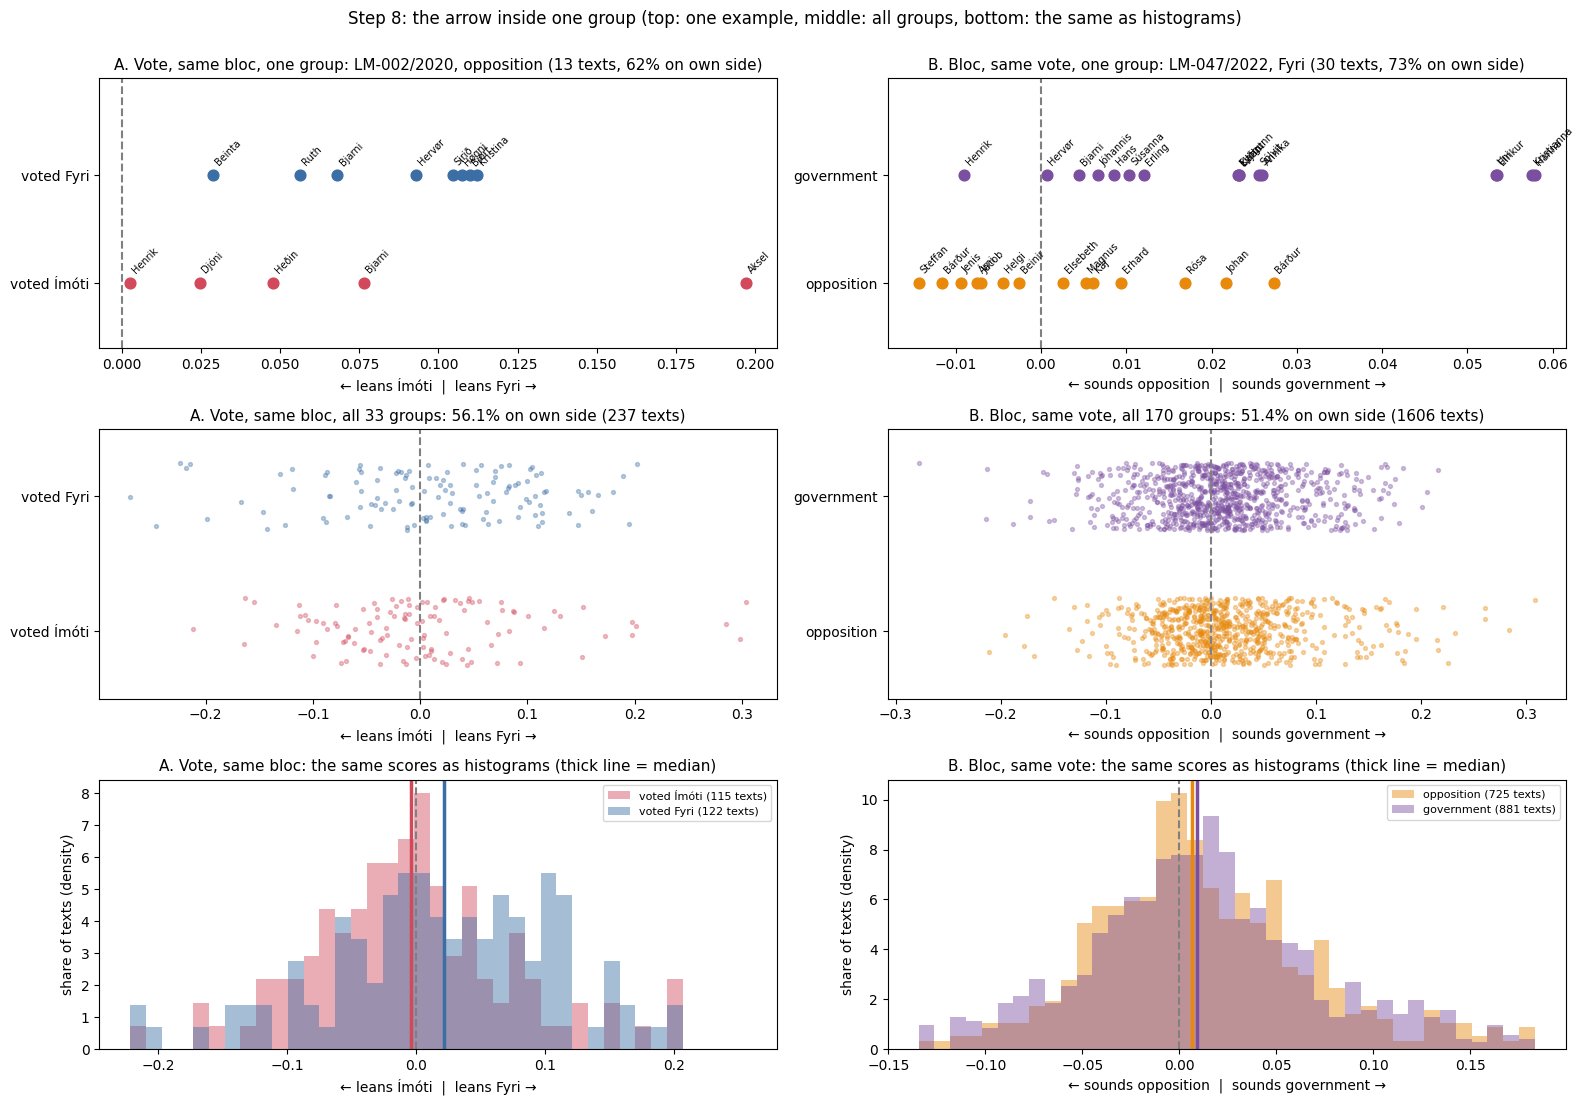

In [47]:
# 8 arrow pictures
def group_scores(label, positive, group_by):
    """Leave-one-out arrow scores inside every group that has at least 2 on each side (as arrow_test_by)."""
    lab = fi[label].to_numpy()
    out = []
    for key, pos in fi.groupby(group_by).indices.items():
        rows_ = fi.index[pos]
        is_pos = lab[rows_] == positive
        if is_pos.sum() >= 2 and (~is_pos).sum() >= 2:
            G = (X[rows_] @ X[rows_].T).toarray()
            out.append((key, rows_, loo_scores(G, is_pos), is_pos))
    return out

BLUE, RED, PURPLE, ORANGE = '#3b6ea5', '#d1495b', '#7b4fa0', '#e8890c'
setups = [('A. Vote, same bloc', 'vote', 'Fyri', ['case_number', 'bloc'], ('voted Ímóti', 'voted Fyri'), (RED, BLUE),
           '← leans Ímóti  |  leans Fyri →'),
          ('B. Bloc, same vote', 'bloc', 'government', ['case_number', 'vote'], ('opposition', 'government'), (ORANGE, PURPLE),
           '← sounds opposition  |  sounds government →')]
rng_plot = np.random.default_rng(0)
fig, axes = plt.subplots(3, 2, figsize=(16, 11))
for col, (name_, label, positive, group_by, ylabels, colours, xlab) in enumerate(setups):
    groups = group_scores(label, positive, group_by)
    # top: the biggest group, with first names (like 7a)
    key, rows_, s, is_pos = max(groups, key=lambda g: len(g[1]))
    ax = axes[0, col]
    for k, m in enumerate((~is_pos, is_pos)):
        ax.scatter(s[m], np.full(m.sum(), k), color=colours[k], s=60)
        for x_, n_ in zip(s[m], fi.loc[rows_[m], 'name']):
            ax.annotate(n_.split()[0], (x_, k), xytext=(0, 7), textcoords='offset points', fontsize=7, rotation=45)
    ax.axvline(0, color='grey', ls='--'); ax.set_ylim(-0.6, 1.9)
    ax.set_yticks([0, 1]); ax.set_yticklabels(ylabels); ax.set_xlabel(xlab)
    right = ((s > 0) == is_pos).mean()
    ax.set_title(f"{name_}, one group: {key[0]}, {key[1]} ({len(rows_)} texts, {right:.0%} on own side)", fontsize=11)
    # bottom: all groups together (like 7b)
    s_all = np.concatenate([g[2] for g in groups]); p_all = np.concatenate([g[3] for g in groups])
    ax = axes[1, col]
    for k, m in enumerate((~p_all, p_all)):
        ax.scatter(s_all[m], k + rng_plot.uniform(-0.25, 0.25, m.sum()), color=colours[k], s=8, alpha=0.35)
    ax.axvline(0, color='grey', ls='--'); ax.set_ylim(-0.5, 1.5)
    ax.set_yticks([0, 1]); ax.set_yticklabels(ylabels); ax.set_xlabel(xlab)
    ax.set_title(f"{name_}, all {len(groups)} groups: {((s_all > 0) == p_all).mean():.1%} on own side "
                 f"({len(s_all)} texts)", fontsize=11)
    # third row: the same scores as two overlapping histograms, with medians
    ax = axes[2, col]
    bins = np.linspace(np.percentile(s_all, 1), np.percentile(s_all, 99), 40)
    for k, m in enumerate((~p_all, p_all)):
        ax.hist(s_all[m], bins=bins, color=colours[k], alpha=0.45, density=True, label=f'{ylabels[k]} ({m.sum()} texts)')
        ax.axvline(np.median(s_all[m]), color=colours[k], lw=2.5)
    ax.axvline(0, color='grey', ls='--')
    ax.set_xlabel(xlab); ax.set_ylabel('share of texts (density)'); ax.legend(fontsize=8)
    ax.set_title(f"{name_}: the same scores as histograms (thick line = median)", fontsize=11)
fig.suptitle('Step 8: the arrow inside one group (top: one example, middle: all groups, bottom: the same as histograms)', y=1.0)
plt.tight_layout(); plt.show()

### 8f. Against the null model

All four tests side by side: the same shuffles as in Step 7c (1,000 times, inside each group). Red line = real share, grey = shuffled. The further right of the grey the red line is, the less it can be luck.

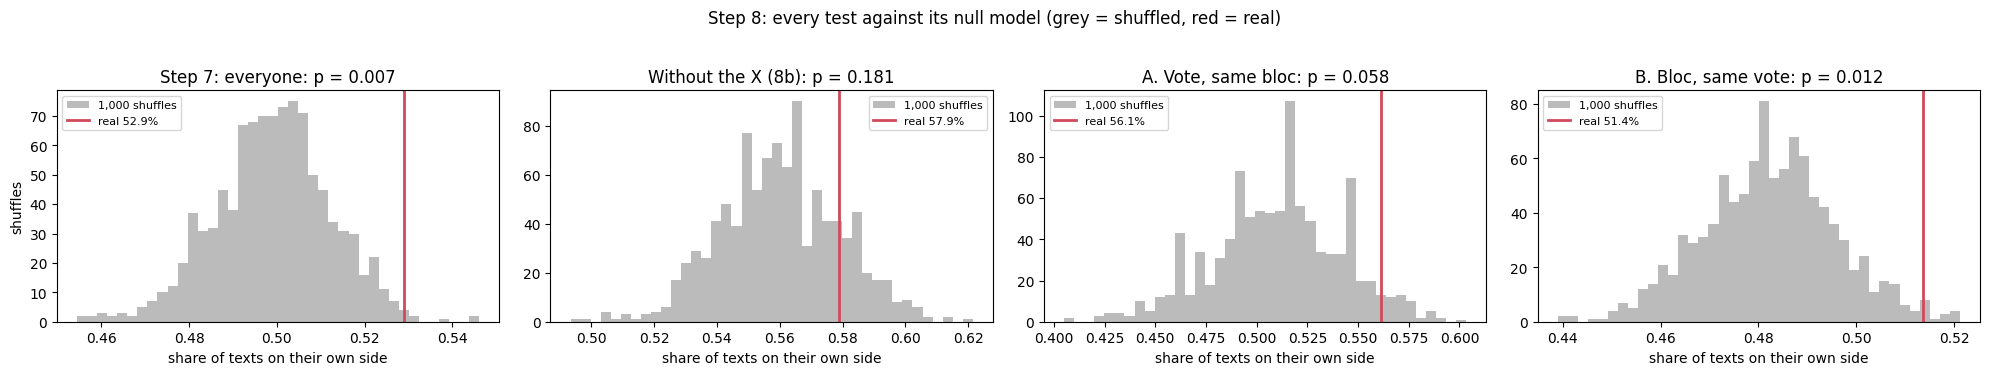

In [48]:
all8 = [('Step 7: everyone', res8['Vote (Step 7)'], null8['Vote (Step 7)']),
        ('Without the X (8b)', res_nox, null_nox),
        ('A. Vote, same bloc', res8['A. Vote, same bloc'], null8['A. Vote, same bloc']),
        ('B. Bloc, same vote', res8['B. Bloc, same vote'], null8['B. Bloc, same vote'])]
fig, axes = plt.subplots(1, 4, figsize=(20, 3.6))
for ax, (name_, res, null) in zip(axes, all8):
    ax.hist(null, bins=40, color='#bbbbbb', label='1,000 shuffles')
    ax.axvline(res['on own side'], color='#d1495b', lw=2, label=f"real {res['on own side']:.1%}")
    ax.set_title(f"{name_}: p = {res['p (vs shuffled)']:.3f}")
    ax.set_xlabel('share of texts on their own side'); ax.legend(fontsize=8)
axes[0].set_ylabel('shuffles')
fig.suptitle('Step 8: every test against its null model (grey = shuffled, red = real)', y=1.03)
plt.tight_layout(); plt.show()


### 8. Niðurstøða

**The signal from Step 7 sits mostly in debates where vote = bloc. We cannot clearly show the vote on its own.**

| test | texts | on own side | null mean | p |
|---|---|---|---|---|
| Step 7: all debates | 1,692 | 52.9% | 49.9% | 0.007 |
| Without the X | 679 | 57.9% | 56.0% | 0.18 |
| A. Vote, same bloc | 237 | 56.1% | 51.0% | 0.06 |
| B. Bloc, same vote | 1,606 | 51.4% | 48.2% | 0.01 |

- **The X:** in **82 of the 133 debates**, everyone voted with their bloc: the government all one way, the opposition all the other. In those debates we can't tell whether someone's words follow their vote or their bloc, because the two are the same (like the stork and the babies).
- **Without the X** (51 debates where someone broke with their bloc): the vote signal is **not significant** (p ≈ 0.18).
- **A. Vote, same bloc:** a **hint** that the vote shows by itself (p ≈ 0.06), but only 237 texts, because members of the same bloc rarely vote differently.
- **B. Bloc, same vote:** the bloc shows a little in the words, even when the vote is the same (p ≈ 0.01).

**So:** the words lean towards the vote (Step 7), but most of that lean can also be explained by government vs opposition. The vote by itself gives only a hint, not a clear result. A real causal answer (what drives what) is beyond this project.

## Step 9: a map of the members

Our question, asked **member by member**. Each member becomes **one dot**, placed by two arrows (like the science ↔ magic map in week 6):
- **x: words vs vote.** ← *words lean against their own vote* | *words lean with their own vote* →. Right = they vote the way their words lean.
- **y: words vs bloc.** ← *sounds like the other bloc* | *sounds like their own bloc* →. Top = they sound like their own bloc (samgonga or andstøða).

Both arrows are the normalised leave-one-out arrow from Steps 7-8.

### 9a. A score per text

Every text (one member in one debate) gets two scores, with the Step 7 recipe:

| score | above 0 means | below 0 means |
|---|---|---|
| **words vs vote** | the words lean to the side the member **voted** | the words lean to the **other** side |
| **words vs bloc** | the words lean to the member's **own bloc** | the words lean to the **other** bloc |

Each debate's scores are divided by their spread, so 1 means "one typical step towards own side" in every debate. That way scores from different debates can be averaged.

In [49]:
lean = loo_scores          # the normalised leave-one-out arrow from Steps 7-8

def debates_with(label, positive):
    """Debates with at least 2 texts on each side, with their dot-product matrix."""
    lab = fi[label].to_numpy()
    use = []
    for _, pos in fi.groupby('case_number').indices.items():
        r = fi.index[pos]
        is_pos = lab[r] == positive
        if is_pos.sum() >= 2 and (~is_pos).sum() >= 2:
            use.append((r, (X[r] @ X[r].T).toarray()))
    return use

def own_side_scores(use, lab, positive):
    """Per text: lean towards its OWN side (+) or the other side (−), in standard units per debate."""
    s = np.full(len(fi), np.nan)
    for r, G in use:
        is_pos = lab[r] == positive
        sc = lean(G, is_pos)
        s[r] = sc / sc.std() * np.where(is_pos, 1, -1)
    return s

vote_lab, bloc_lab = fi['vote'].to_numpy(), fi['bloc'].to_numpy()
use_vote, use_bloc = debates_with('vote', 'Fyri'), debates_with('bloc', 'government')
fi['words_vote'] = own_side_scores(use_vote, vote_lab, 'Fyri')
fi['words_bloc'] = own_side_scores(use_bloc, bloc_lab, 'government')
overview9 = pd.DataFrame([
    {'arrow': 'words vs vote', 'question per text': 'do the words lean to the side the member VOTED?',
     'texts': int(fi['words_vote'].notna().sum()), 'debates': len(use_vote), 'lean to own side': (fi['words_vote'] > 0).sum() / fi['words_vote'].notna().sum()},
    {'arrow': 'words vs bloc', 'question per text': 'do the words lean to the member\'s own BLOC?',
     'texts': int(fi['words_bloc'].notna().sum()), 'debates': len(use_bloc), 'lean to own side': (fi['words_bloc'] > 0).sum() / fi['words_bloc'].notna().sum()}])
display(overview9.style.hide(axis='index').format({'lean to own side': '{:.1%}'}))


arrow,question per text,texts,debates,lean to own side
words vs vote,do the words lean to the side the member VOTED?,1692,133,52.9%
words vs bloc,do the words lean to the member's own BLOC?,2979,269,49.1%


### 9b. One score per member, and what luck looks like

**Member score** = the average of all their text scores (one for each arrow). We only keep members with at least **10 texts** on the words-vs-vote arrow.

**Luck:** with few texts, a member can get a high or low score by luck alone. So we shuffle the votes (and, separately, the blocs) inside each debate **500 times** and recompute every member's score each time. That gives each member 500 "luck scores" (their null model).
A member **beats chance** if their real score is higher than 97.5% of their luck scores, or lower than 97.5% of them.

In [50]:
MIN_TEXTS = 10

def member_means(scores):
    return pd.Series(scores, index=fi.index).groupby(fi['mp_id']).mean()

real_x, real_y = member_means(fi['words_vote']), member_means(fi['words_bloc'])
n_texts = fi['words_vote'].notna().groupby(fi['mp_id']).sum()
keep = n_texts[n_texts >= MIN_TEXTS].index

rng = np.random.default_rng(1)
null_x, null_y = [], []
for _ in range(500):
    for use, lab, positive, store in ((use_vote, vote_lab, 'Fyri', null_x), (use_bloc, bloc_lab, 'government', null_y)):
        l = lab.copy()
        for r, _G in use:
            l[r] = rng.permutation(l[r])
        store.append(member_means(own_side_scores(use, l, positive)))
null_x, null_y = pd.DataFrame(null_x), pd.DataFrame(null_y)

members_map = pd.DataFrame({
    'name': fi.groupby('mp_id')['name'].first(),
    'party': fi.groupby('mp_id')['party'].agg(lambda s: s.mode().iloc[0]),
    'texts': n_texts,
    'words_vote': real_x, 'words_bloc': real_y,
    'beats chance (vote)': (real_x > null_x.quantile(0.975)) | (real_x < null_x.quantile(0.025)),
}).loc[keep]
print(f'{len(members_map)} members with at least {MIN_TEXTS} texts')
print(f"beat chance on words vs vote: {members_map['beats chance (vote)'].sum()} "
      f"(right side: {(members_map['beats chance (vote)'] & (members_map['words_vote'] > 0)).sum()}, "
      f"left side: {(members_map['beats chance (vote)'] & (members_map['words_vote'] < 0)).sum()})")
print(f'by chance alone we would expect about {0.05 * len(members_map):.0f}')

42 members with at least 10 texts
beat chance on words vs vote: 9 (right side: 9, left side: 0)
by chance alone we would expect about 2


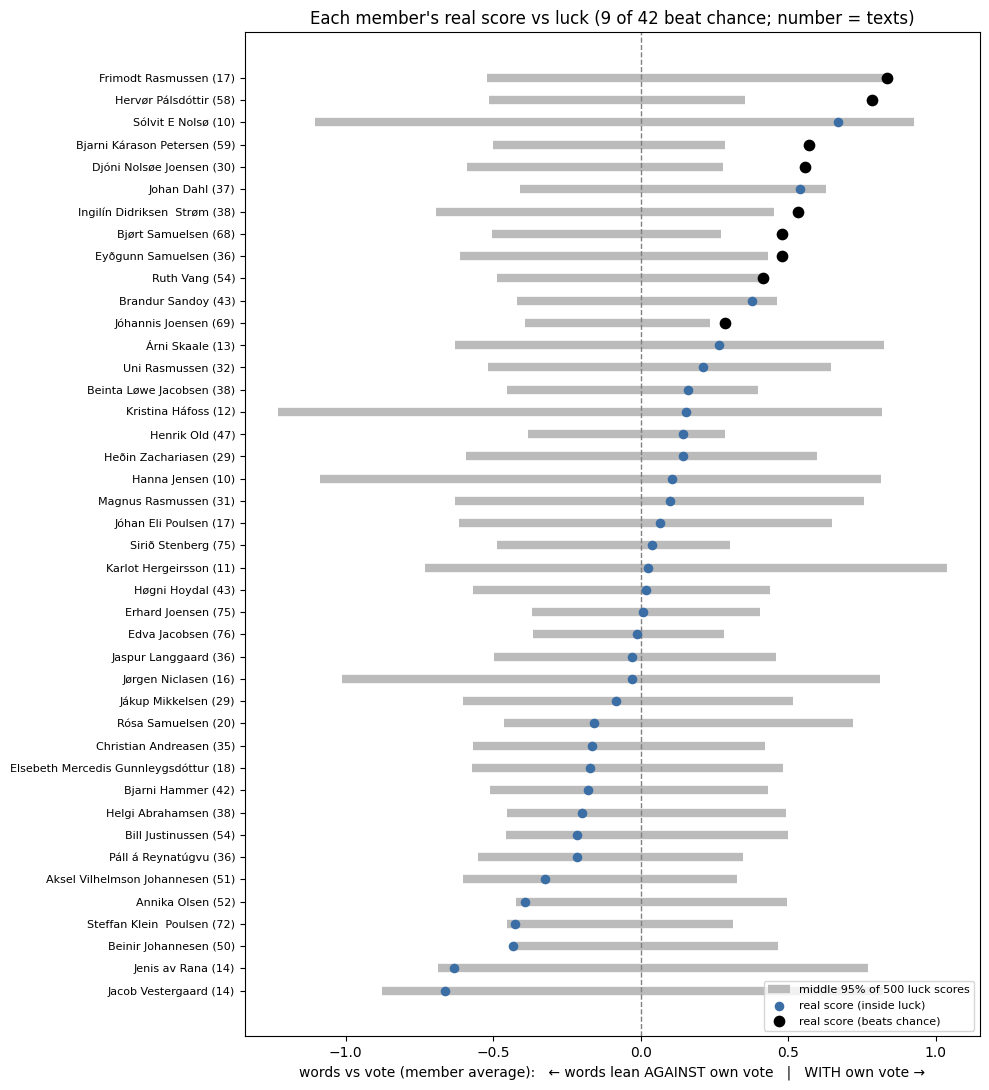

In [51]:
# 9b picture: each member's real score against their 500 luck scores
order = members_map.sort_values('words_vote').index
lo, hi = null_x[order].quantile(0.025), null_x[order].quantile(0.975)
fig, ax = plt.subplots(figsize=(10, 11))
ypos = np.arange(len(order))
ax.hlines(ypos, lo, hi, color='#bbbbbb', lw=6, label='middle 95% of 500 luck scores')
beat = members_map.loc[order, 'beats chance (vote)'].to_numpy()
ax.scatter(members_map.loc[order, 'words_vote'][~beat], ypos[~beat], color='#3b6ea5', s=35, zorder=3, label='real score (inside luck)')
ax.scatter(members_map.loc[order, 'words_vote'][beat], ypos[beat], color='black', s=55, zorder=3, label='real score (beats chance)')
ax.axvline(0, color='grey', ls='--', lw=1)
ax.set_yticks(ypos)
ax.set_yticklabels([f"{members_map.at[m, 'name']} ({members_map.at[m, 'texts']})" for m in order], fontsize=8)
ax.set_xlabel('words vs vote (member average):   ← words lean AGAINST own vote   |   WITH own vote →')
ax.set_title(f"Each member's real score vs luck ({int(beat.sum())} of {len(order)} beat chance; number = texts)")
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

### 9c. The map

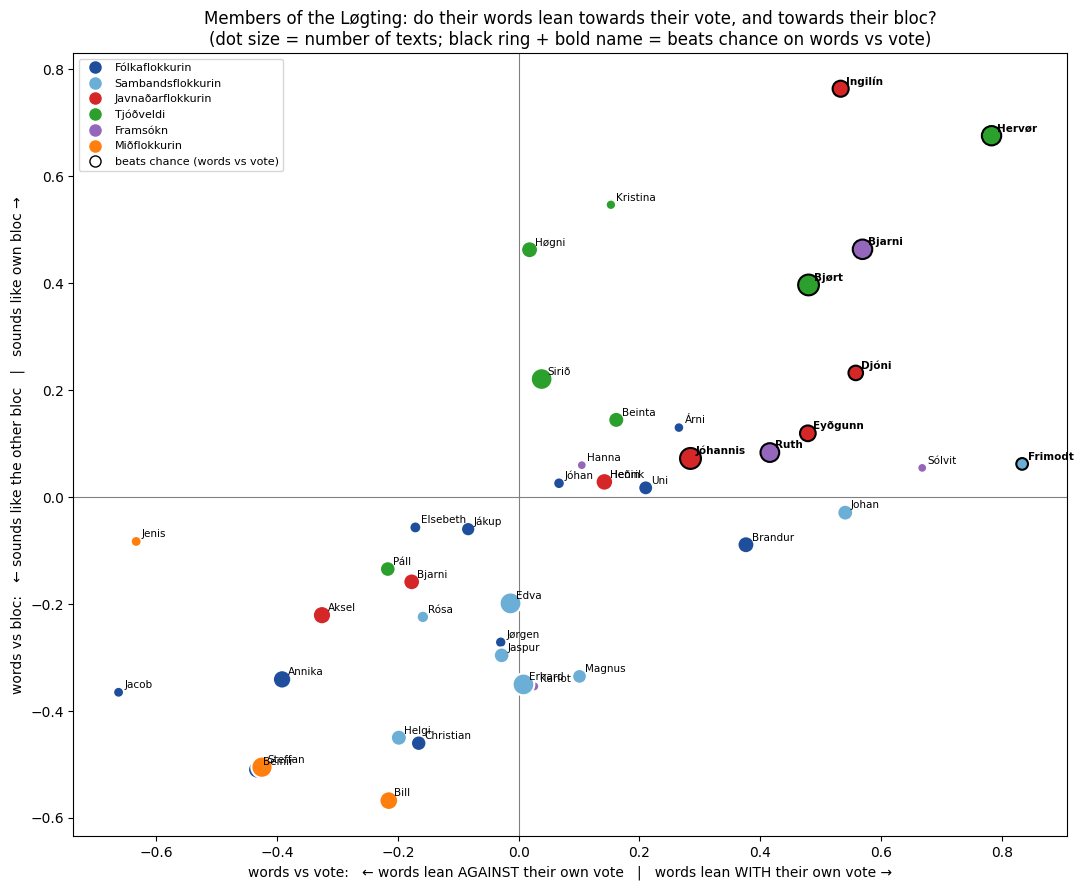

In [52]:
party_col = {'Fólkaflokkurin': '#1f4e9c', 'Sambandsflokkurin': '#6baed6', 'Javnaðarflokkurin': '#d62728',
             'Tjóðveldi': '#2ca02c', 'Framsókn': '#9467bd', 'Miðflokkurin': '#ff7f0e', 'Sjálvstýri': '#e6c229'}

fig, ax = plt.subplots(figsize=(11, 9))
ax.axvline(0, color='grey', lw=0.8); ax.axhline(0, color='grey', lw=0.8)
for pname, g in members_map.groupby('party'):
    ax.scatter(g['words_vote'], g['words_bloc'], s=20 + 3 * g['texts'], color=party_col.get(pname, 'grey'),
               edgecolor=np.where(g['beats chance (vote)'], 'black', 'white'), linewidth=1.5, zorder=3)
for _, r in members_map.iterrows():
    ax.annotate(r['name'].split()[0], (r['words_vote'], r['words_bloc']), xytext=(4, 3), textcoords='offset points',
                fontsize=7.5, fontweight='bold' if r['beats chance (vote)'] else 'normal', zorder=4)
ax.set_xlabel('words vs vote:   ← words lean AGAINST their own vote   |   words lean WITH their own vote →')
ax.set_ylabel('words vs bloc:   ← sounds like the other bloc   |   sounds like own bloc →')
ax.set_title('Members of the Løgting: do their words lean towards their vote, and towards their bloc?\n'
             '(dot size = number of texts; black ring + bold name = beats chance on words vs vote)')
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker='o', ls='', color=col, markersize=8, label=pn) for pn, col in party_col.items()
           if pn in set(members_map['party'])]
handles += [Line2D([], [], marker='o', ls='', color='white', markeredgecolor='black', markersize=8, label='beats chance (words vs vote)')]
ax.legend(handles=handles, loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

In [53]:
print('Members who beat chance on words vs vote:')
(members_map[members_map['beats chance (vote)']]
 .sort_values('words_vote', ascending=False)[['name', 'party', 'texts', 'words_vote', 'words_bloc']]
 .round(2).style.hide(axis='index'))

Members who beat chance on words vs vote:


name,party,texts,words_vote,words_bloc
Frimodt Rasmussen,Sambandsflokkurin,17,0.830000,0.060000
Hervør Pálsdóttir,Tjóðveldi,58,0.780000,0.680000
Bjarni Kárason Petersen,Framsókn,59,0.570000,0.460000
Djóni Nolsøe Joensen,Javnaðarflokkurin,30,0.560000,0.230000
Ingilín Didriksen Strøm,Javnaðarflokkurin,38,0.530000,0.760000
Bjørt Samuelsen,Tjóðveldi,68,0.480000,0.400000
Eyðgunn Samuelsen,Javnaðarflokkurin,36,0.480000,0.120000
Ruth Vang,Framsókn,54,0.420000,0.080000
Jóhannis Joensen,Javnaðarflokkurin,69,0.280000,0.070000


### 9. Niðurstøða

**Member by member: for a few members the words lean clearly towards how they vote, for most we can't tell, and for nobody the other way. But after Step 8 we can't say whether that lean is their vote or their bloc.**

- **9 of 42 members** have words that lean towards their own vote more than luck gives (black dots in 9b, black rings on the map). By luck alone we would expect about 2.
- **No member** is clearly on the left side: nobody systematically says one thing and votes another.
- **Most members are "can't tell"**, often because they have few texts (wide grey bars in 9b).

**The catch from Step 8:** the x-axis uses the Step 7 arrow (everyone together, all debates). In most debates everyone voted with their bloc (the X), so "leans towards own vote" can also mean "leans towards own bloc". And 8 of the 9 come from **Tjóðveldi, Javnaðarflokkurin and Framsókn**, who were in **opposition** for most of the period (until Dec 2022), plus Frimodt Rasmussen (Sambandsflokkurin). That fits both readings:
- the opposition argues its stance in its words, **or**
- the opposition simply **sounds like the opposition**, and in most debates the opposition all voted the same way.

The data cannot separate the two (Step 8: when vote and bloc differ, the signal is only a hint).

*Ruth Vang, who sounded Fyri in the work-week debate (Step 3c), is one of the 9.*

**In one sentence:** for 9 of 42 løgtingslimir the words lean towards how they vote more than luck would give (about 2 expected), nobody leans the other way, and for the rest we can't tell; but since vote and bloc are mostly the same split, this may be their bloc speaking as much as their vote.

## Step 10: which debates match best, and which worst?

**Step 10 is Step 7, but with one pile per debate instead of one big pile.**

In Step 7 every text got a guess (its words lean to the Fyri side or the Ímóti side), and we put all 1,692 guesses in **one pile**: 52.9% were right.
Here we use **the same guesses**, but count them **debate by debate**. The question: are some debates much better (or worse) than the 52.9% average?

<div style="background-color:rgba(201,185,138,0.15); border-left:5px solid #c9b98a; padding:10px 14px;">

**Example**

| | texts | guessed right | match |
|---|---|---|---|
| Step 7: all debates in one pile | 1,692 | 895 | **52.9%** |
| Step 10: labour-market measures (LM-031/2020) | 22 | 17 | **77%** |
| Step 10: supplementary budget (LM-022/2021) | 15 | 11 | **73%** |
| Step 10: financial rules (LM-125/2021) | 7 | 0 | **0%** |

</div>

**Luck:** a debate with 7 speakers can easily hit 0% or 100% by luck. So for each debate we also shuffle its votes 1,000 times; **p** = how often the shuffled votes matched at least as well. A small p means that debate's match is hard to get by luck.

In [54]:
case_info = votes.drop_duplicates('case_number').set_index('case_number')[['case_title', 'case_type']]
rng5 = np.random.default_rng(2)
rows5 = []
for r, G in use_vote:
    is_f = vote_lab[r] == 'Fyri'
    match = ((lean(G, is_f) > 0) == is_f).mean()
    null = []
    for _ in range(1000):
        pf = rng5.permutation(is_f)
        null.append(((lean(G, pf) > 0) == pf).mean())
    case = fi.loc[r[0], 'case_number']
    rows5.append({'case': case, 'title': case_info.loc[case, 'case_title'], 'type': case_info.loc[case, 'case_type'],
                  'members': len(r), 'Fyri': int(is_f.sum()), 'Ímóti': int((~is_f).sum()),
                  'match': match, 'p': (np.array(null) >= match).mean()})
debates5 = pd.DataFrame(rows5)
print(f'{len(debates5)} debates | match better than chance (p < 0.05): {(debates5["p"] < 0.05).sum()} '
      f'(by chance alone about {0.05 * len(debates5):.0f})')

show5 = lambda d: (d.assign(title=d['title'].str.replace('Uppskot til ', '', regex=False).str[:75])
                   [['case', 'title', 'members', 'Fyri', 'Ímóti', 'match', 'p']]
                   .style.hide(axis='index').format({'match': '{:.0%}', 'p': '{:.3f}'}))

133 debates | match better than chance (p < 0.05): 4 (by chance alone about 7)


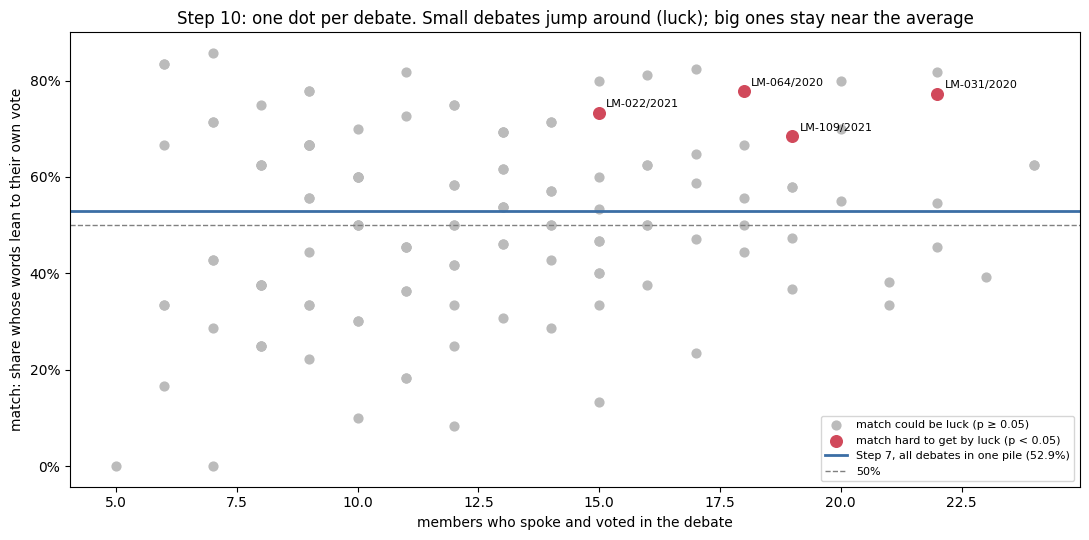

In [55]:
# Step 10 picture: every debate as one dot
fig, ax = plt.subplots(figsize=(11, 5.5))
sig = debates5['p'] < 0.05
ax.scatter(debates5.loc[~sig, 'members'], debates5.loc[~sig, 'match'], color='#bbbbbb', s=40, label='match could be luck (p ≥ 0.05)')
ax.scatter(debates5.loc[sig, 'members'], debates5.loc[sig, 'match'], color='#d1495b', s=70, label='match hard to get by luck (p < 0.05)')
overall = ((fi['words_vote'] > 0).sum() / fi['words_vote'].notna().sum())
ax.axhline(overall, color='#3b6ea5', lw=2, label=f'Step 7, all debates in one pile ({overall:.1%})')
ax.axhline(0.5, color='grey', ls='--', lw=1, label='50%')
for _, r in debates5[sig].iterrows():
    ax.annotate(r['case'], (r['members'], r['match']), xytext=(5, 4), textcoords='offset points', fontsize=8)
ax.set_xlabel('members who spoke and voted in the debate')
ax.set_ylabel('match: share whose words lean to their own vote')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('Step 10: one dot per debate. Small debates jump around (luck); big ones stay near the average')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

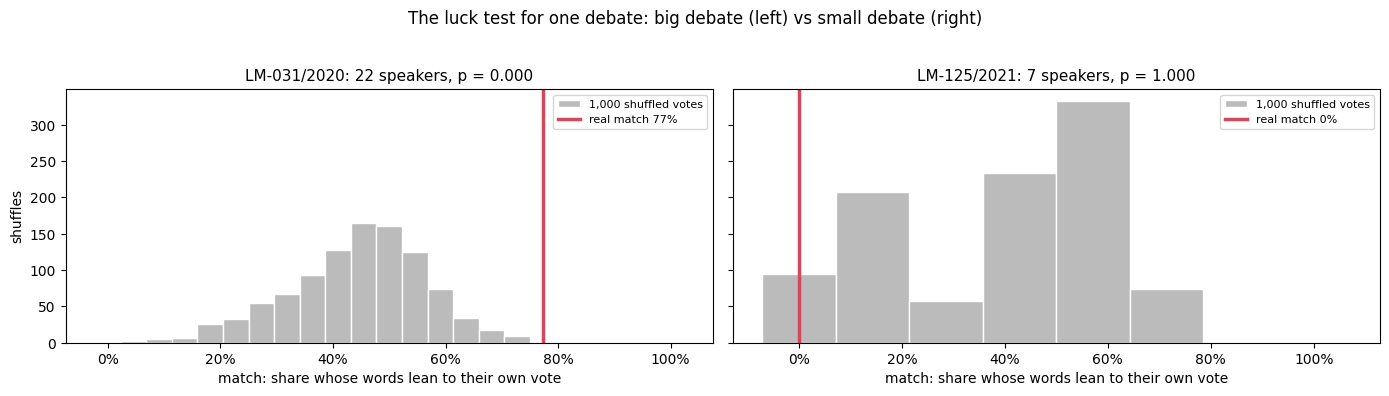

In [56]:
# Step 10 luck test: what 1,000 shuffles look like in a big and a small debate
examples = ['LM-031/2020', 'LM-125/2021']
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
rng_ex = np.random.default_rng(5)
for ax, case in zip(axes, examples):
    r, G = next((r, G) for r, G in use_vote if fi.loc[r[0], 'case_number'] == case)
    is_f = vote_lab[r] == 'Fyri'
    real = ((lean(G, is_f) > 0) == is_f).mean()
    null = []
    for _ in range(1000):
        pf = rng_ex.permutation(is_f)
        null.append(((lean(G, pf) > 0) == pf).mean())
    null = np.array(null)
    n = len(r)                                    # with n speakers the match can only be 0/n, 1/n, ..., n/n
    ax.hist(null, bins=(np.arange(n + 2) - 0.5) / n, color='#bbbbbb', edgecolor='white', label='1,000 shuffled votes')
    ax.axvline(real, color='#d1495b', lw=2.5, label=f'real match {real:.0%}')
    ax.set_title(f"{case}: {len(r)} speakers, p = {(null >= real).mean():.3f}", fontsize=11)
    ax.set_xlabel('match: share whose words lean to their own vote')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    ax.legend(fontsize=8)
axes[0].set_ylabel('shuffles')
fig.suptitle('The luck test for one debate: big debate (left) vs small debate (right)', y=1.03)
plt.tight_layout(); plt.show()

### 10a. Top 10: where words and votes match best

Sorted by p, so the most convincing debates come first (a small debate can reach a high match by luck).

In [57]:
show5(debates5.sort_values(['p', 'members'], ascending=[True, False]).head(10))

case,title,members,Fyri,Ímóti,match,p
LM-031/2020,løgtingslóg um broyting í løgtingslóg um arbeiðsfremjandi tiltøk (Broytt ti,22,11,11,77%,0.001
LM-022/2021,eykajáttanarløgtingslóg fyri oktober 2021-2,15,8,7,73%,0.004
LM-109/2021,løgtingslóg um broyting í løgtingslóg um skatting av vinningi frá sølu av v,19,10,9,68%,0.022
LM-064/2020,"løgtingslóg um broyting í løgtingslóg um Húsalánsgrunn (Víðkan av stýri, he",18,13,5,78%,0.032
LM-037/2020,løgtingslóg um broyting í løgtingslóg um almenna heilsutrygd (Heilsutrygdar,7,2,5,86%,0.050
LM-075/2022,Løgtingslóg um broyting í løgtingslóg um sjófeingi (Sjófeingislógin) (Leing,12,8,4,75%,0.063
LM-062/2022,ríkislógartilmæli um at seta í gildi fyri Føroyar Anordning om ikrafttræden,6,4,2,83%,0.076
LM-108/2021,løgtingslóg um broyting í løgtingslóg um meirvirðisgjald (Meirvirðisgjaldsl,8,5,3,75%,0.078
LM-052/2022,ríkislógartilmæli um at seta í gildi fyri Føroyar Anordning om ikrafttræden,11,8,3,82%,0.081
LM-131/2021,samtyktar um játtanarkarmar á løgtingsfíggjarlógini fyri 2023,24,11,13,62%,0.084


### 10b. Bottom 10: where the words lean the other way

Sorted by match, lowest first.

In [58]:
show5(debates5.sort_values(['match', 'members'], ascending=[True, False]).head(10))

case,title,members,Fyri,Ímóti,match,p
LM-125/2021,samtyktar um fíggjarpolitiskt regluverk,7,3,4,0%,1.000
LM-077/2021,ríkislógartilmæli um at seta í gildi fyri Føroyar Anordning om ikrafttræden,5,3,2,0%,1.000
LM-122/2021,samtyktar um miðvísar íløgur og átøk til at menna føroyska málið í 21. øld,12,8,4,8%,0.990
LM-055/2021,eykajáttanarløgtingslóg fyri januar 2022-2,10,5,5,10%,0.986
LM-030/2021,løgtingslóg um broyting í løgtingslóg um sjófeingi (Sjófeingislógin) (Veiði,15,7,8,13%,0.984
LM-079/2021,samtyktar um kemikaliulóg (evnindalóg),6,2,4,17%,1.000
LM-010/2021,samtyktar um at byggja stórhøll til innandura ítrótt og størri tiltøk,11,4,7,18%,0.950
LM-080/2021,løgtingslóg um broyting í løgtingslóg um sjófeingi (Sjófeingislógin) (Umleg,11,6,5,18%,0.912
LM-044/2020,løgtingslóg um yvirvøku við vakmyndatóli,9,5,4,22%,0.860
LM-135/2020,samtyktar um játtanarkarmar á løgtingsfíggjarlógini fyri 2022,17,8,9,24%,0.915


### 10c. By type of case

In [59]:
(debates5.groupby('type')
 .agg(debates=('case', 'size'), average_match=('match', 'mean'), better_than_chance=('p', lambda s: (s < 0.05).sum()))
 .sort_values('average_match', ascending=False)
 .style.format({'average_match': '{:.0%}'}))

,debates,average_match,better_than_chance
type,,,
Uppskot til Tingskipan,1,71%,0
Fíggjarlógaruppskot,13,57%,1
Lógaruppskot,62,53%,3
Uppskot til samtyktar,51,48%,0
Ríkislógartilmæli,6,48%,0


### 10. Niðurstøða

**The link is spread thinly over many debates; it is not a few debates carrying it.** Only 4 of 133 debates match better than chance, where luck alone would give about 7. A single debate has too few speakers to show a weak effect.

**The clearest case:** LM-031/2020, a change to the law on labour-market measures (*arbeiðsfremjandi tiltøk*): 22 members, 11 on each side, and 77% of them lean towards their own vote (p = 0.001: very unlikely by luck, even among 133 debates). Next: a supplementary budget, LM-022/2021 (73%, p = 0.004). Both were **close votes**: LM-031/2020 passed 16–2–11, LM-022/2021 fell 11–0–13.

**By type:** budgets (57%) and laws (53%) match a little; resolutions (*uppskot til samtyktar*, often from the opposition) do not (48%). Small differences, so only a hint.

**The catch from Step 8:** like Step 9, this uses the Step 7 arrow (everyone together). We checked the two best debates, and **both are X debates**: in LM-031/2020 all 11 Fyri speakers were samgonga and all 11 Ímóti speakers andstøða; in LM-022/2021 all 8 Fyri speakers were andstøða and all 7 Ímóti speakers samgonga. So in the debates that "match best", the words may just as well follow the **bloc** as the vote.

## Step 11: figures for the report

All results from Steps 4–8 in one place, drawn for the paper. Nothing new is calculated here: the figures use the results and shuffles from the steps above.

**Three groups, one question each:**
1. *Do members who vote alike talk alike?* (Steps 4–6: the pairs gap)
2. *Does a speech lean towards its own vote?* (Step 7: the arrow)
3. *Is it the vote or the bloc?* (Step 8: bloc-line votes excluded, bloc held fixed, vote held fixed)

**Bloc-line votes** = proposals where every government member who spoke voted one way and every opposition member the other (the X in Step 8).

The figures are saved in `figures_for_report/`.

In [60]:
import os, matplotlib.ticker as mticker, matplotlib.patches as mpatches, matplotlib.lines as mlines
os.makedirs('figures_for_report', exist_ok=True)

def p_text(p):
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}' if p < 0.01 else f'p = {p:.2f}'

# (heading, what is measured, [(label, result, shuffles), ...])
report_tests = [
    ('Do members who vote alike talk alike?', 'gap', [
        ('TF-IDF, all documents', res_all, null_all),
        ('TF-IDF, 300+ words', res_long, null_long),
        ('PPMI, all documents', res6_ppmi, null6_ppmi)]),
    ('Does a speech lean towards its own vote?', 'on own side', [
        ('TF-IDF, all documents', res7_all, null7_all),
        ('TF-IDF, 300+ words', res7_long, null7_long),
        ('PPMI, all documents', res7_ppmi, null7_ppmi)]),
    ('Is it the vote or the bloc?', 'on own side', [
        ('Vote, bloc-line votes excluded', res_nox, null_nox),
        ('Vote, bloc held fixed', res8['A. Vote, same bloc'], null8['A. Vote, same bloc']),
        ('Bloc, vote held fixed', res8['B. Bloc, same vote'], null8['B. Bloc, same vote'])]),
]

def number_text(key, res, null):
    real = res[key]
    if key == 'gap':
        return f"{real:+.4f} (chance {np.mean(null):+.4f}),  {p_text(res['p (vs shuffled)'])}"
    return f"{real:.1%} (chance {np.mean(null):.1%}),  {p_text(res['p (vs shuffled)'])}"

pd.DataFrame([{'group': h, 'test': lab, 'result': number_text(key, res, null)}
              for h, key, rows in report_tests for lab, res, null in rows]).style.hide(axis='index')

group,test,result
Do members who vote alike talk alike?,"TF-IDF, all documents","+0.0011 (chance -0.0001), p = 0.20"
Do members who vote alike talk alike?,"TF-IDF, 300+ words","+0.0019 (chance -0.0001), p = 0.11"
Do members who vote alike talk alike?,"PPMI, all documents","-0.0010 (chance -0.0001), p = 0.65"
Does a speech lean towards its own vote?,"TF-IDF, all documents","52.9% (chance 49.9%), p = 0.007"
Does a speech lean towards its own vote?,"TF-IDF, 300+ words","53.9% (chance 48.7%), p < 0.001"
Does a speech lean towards its own vote?,"PPMI, all documents","54.0% (chance 49.7%), p < 0.001"
Is it the vote or the bloc?,"Vote, bloc-line votes excluded","57.9% (chance 56.0%), p = 0.18"
Is it the vote or the bloc?,"Vote, bloc held fixed","56.1% (chance 51.0%), p = 0.06"
Is it the vote or the bloc?,"Bloc, vote held fixed","51.4% (chance 48.2%), p = 0.01"


### 11a. The main figure: box plots

One row per test. **Grey box plot** = the 1,000 shuffles (box = middle 50%, line = median, whiskers = middle 95%). **Black dot** = the real result. Dot outside the whiskers = more than chance.

Each group has its own x-axis: group 1 is a gap in cosine, groups 2 and 3 are a share of speeches. Each test has its own chance level, written in brackets on the right.

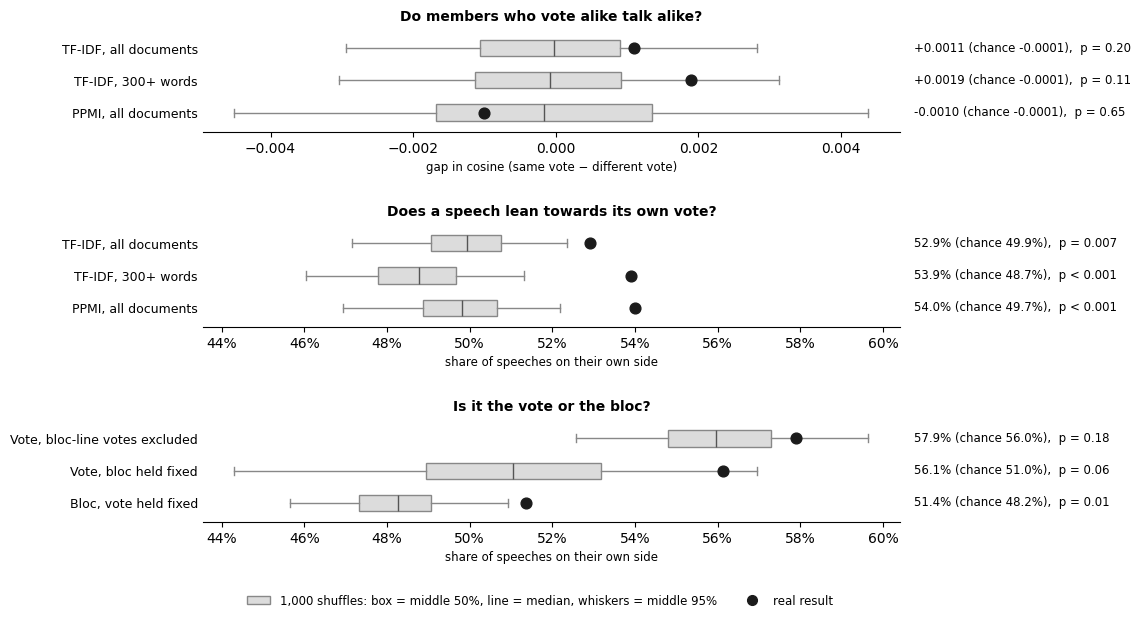

In [61]:
fig, axes = plt.subplots(3, 1, figsize=(9, 6.4), gridspec_kw={'hspace': 0.9})
for g, (ax, (heading, key, rows)) in enumerate(zip(axes, report_tests)):
    ys = [2, 1, 0]
    for y, (label, res, null) in zip(ys, rows):
        null = np.asarray(null)
        lo, q1, med, q3, hi = np.percentile(null, [2.5, 25, 50, 75, 97.5])
        ax.bxp([dict(whislo=lo, q1=q1, med=med, q3=q3, whishi=hi, fliers=[])], positions=[y], widths=0.5,
               orientation='horizontal', showfliers=False, patch_artist=True, manage_ticks=False,
               boxprops=dict(facecolor='#dcdcdc', edgecolor='#888'), medianprops=dict(color='#555'),
               whiskerprops=dict(color='#888'), capprops=dict(color='#888'), zorder=1)
        ax.scatter(res[key], y, s=60, color='#1b1b1b', zorder=3)
        ax.annotate(number_text(key, res, null), xy=(1.02, y), xycoords=('axes fraction', 'data'), va='center', fontsize=8.5)
    ax.set_yticks(ys); ax.set_yticklabels([r[0] for r in rows], fontsize=9)
    ax.tick_params(axis='y', length=0); ax.set_ylim(-0.6, 2.6)
    ax.set_title(heading, fontsize=10, fontweight='bold')
    ax.set_xlabel('gap in cosine (same vote − different vote)' if key == 'gap' else 'share of speeches on their own side', fontsize=8.5)
    if key != 'gap':
        ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
    ax.spines[['top', 'right', 'left']].set_visible(False)
x0 = min(a.get_xlim()[0] for a in axes[1:]); x1 = max(a.get_xlim()[1] for a in axes[1:])
for a in axes[1:]:
    a.set_xlim(x0, x1)
fig.legend(handles=[mpatches.Patch(facecolor='#dcdcdc', edgecolor='#888', label='1,000 shuffles: box = middle 50%, line = median, whiskers = middle 95%'),
                    mlines.Line2D([], [], color='#1b1b1b', marker='o', ls='', markersize=7, label='real result')],
           loc='lower center', ncol=2, fontsize=8.5, frameon=False, bbox_to_anchor=(0.5, -0.04))
plt.show()

### 11b. The same tests as histograms (3 × 3)

The same nine tests, but each with its full histogram of shuffles (like Step 8f). **Grey** = 1,000 shuffles, **black line** = the real result. Each panel has its own x-axis, so compare each line only with its own grey.

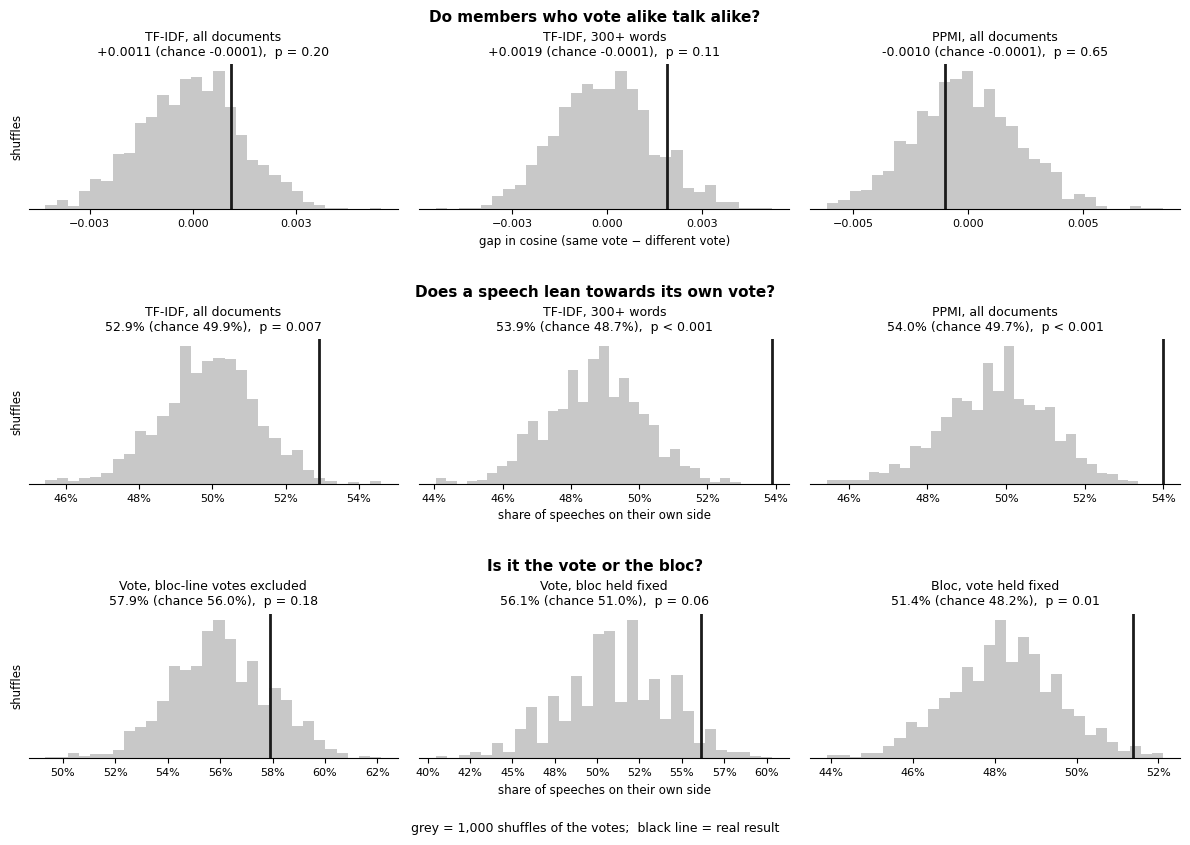

In [62]:
fig, axes = plt.subplots(3, 3, figsize=(12, 8.2))
for r, (heading, key, rows) in enumerate(report_tests):
    for c, (label, res, null) in enumerate(rows):
        ax = axes[r, c]
        null = np.asarray(null)
        ax.hist(null, bins=30, color='#c8c8c8')
        ax.axvline(res[key], color='#1b1b1b', lw=2)
        if key == 'gap':
            ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
        else:
            ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
        ax.set_title(f"{label}\n{number_text(key, res, null)}", fontsize=9)
        ax.set_yticks([]); ax.tick_params(axis='x', labelsize=8)
        ax.spines[['top', 'right', 'left']].set_visible(False)
    axes[r, 0].set_ylabel('shuffles', fontsize=8.5)
    axes[r, 1].set_xlabel('gap in cosine (same vote − different vote)' if key == 'gap' else 'share of speeches on their own side', fontsize=8.5)
plt.tight_layout(rect=(0, 0.03, 1, 1), h_pad=4.2)
for r, (heading, _, _) in enumerate(report_tests):
    fig.text(0.5, axes[r, 1].get_position().y1 + 0.052, heading, ha='center', fontsize=11, fontweight='bold')
fig.text(0.5, 0.005, 'grey = 1,000 shuffles of the votes;  black line = real result', ha='center', fontsize=9)
plt.show()

### 11c. Vote or bloc, in all three versions

In Step 8 the vote-or-bloc tests were run with **TF-IDF on all documents** only. Here we run them also with **TF-IDF on 300+ words** and with **PPMI**, so each test has the same three versions as Steps 4–7.

- **Bloc-line votes excluded:** Step 7 (vote) on the 51 proposals that are not bloc-line votes.
- **Bloc held fixed:** for vs against, inside one bloc (government only, or opposition only).
- **Vote held fixed:** government vs opposition, inside one vote (for only, or against only). Here a document is correctly placed if it is closer to its **own bloc**.

Same rules as Step 8: at least 2 documents on each side per group, 1,000 shuffles inside each group (seed 1).

In [63]:
def arrow_test_by_version(label, positive, group_by, D, keep, n_shuffles=1000, seed=1):
    """Step 8's arrow_test_by, but for any document vectors D and any subset of documents (keep)."""
    lab = fi[label].to_numpy()
    use = []
    sub = fi[keep]
    for _, pos in sub.groupby(group_by).indices.items():
        rows_ = sub.index[pos]
        is_pos = lab[rows_] == positive
        if is_pos.sum() >= 2 and (~is_pos).sum() >= 2:
            G = D[rows_] @ D[rows_].T
            use.append((rows_, G.toarray() if hasattr(G, 'toarray') else G))

    def share_right(lab):
        return np.concatenate([(loo_scores(G, lab[r] == positive) > 0) == (lab[r] == positive) for r, G in use]).mean()

    real_ = share_right(lab)
    rng = np.random.default_rng(seed)
    null = []
    for _ in range(n_shuffles):
        l = lab.copy()
        for r, _G in use:
            l[r] = rng.permutation(l[r])
        null.append(share_right(l))
    null = np.array(null)
    return {'texts': sum(len(r) for r, _ in use), 'groups': len(use), 'on own side': real_,
            'shuffled (average)': null.mean(), 'p (vs shuffled)': (null >= real_).mean()}, null

versions = [('TF-IDF, all documents', X, all_rows), ('TF-IDF, 300+ words', X, long_rows), ('PPMI, all documents', D, all_rows)]
bloc_tests = {'Vote, bloc-line votes excluded': [], 'Vote, bloc held fixed': [], 'Bloc, vote held fixed': []}
for vname, Dm, keep in versions:
    bloc_tests['Vote, bloc-line votes excluded'].append((vname, *arrow_test(Dm, no_x & keep)[:2]))
    bloc_tests['Vote, bloc held fixed'].append((vname, *arrow_test_by_version('vote', 'Fyri', ['case_number', 'bloc'], Dm, keep)))
    bloc_tests['Bloc, vote held fixed'].append((vname, *arrow_test_by_version('bloc', 'government', ['case_number', 'vote'], Dm, keep)))

pd.DataFrame([{'test': t, 'version': v, 'texts': r['texts'], 'groups': r.get('groups', r.get('debates')),
               'guessed right': r['on own side'], 'null mean (shuffled)': r['shuffled (average)'], 'p': r['p (vs shuffled)']}
              for t, rows in bloc_tests.items() for v, r, n in rows]
            ).style.hide(axis='index').format({'guessed right': '{:.1%}', 'null mean (shuffled)': '{:.1%}', 'p': '{:.3f}'})

test,version,texts,groups,guessed right,null mean (shuffled),p
"Vote, bloc-line votes excluded","TF-IDF, all documents",679,51,57.9%,56.0%,0.181
"Vote, bloc-line votes excluded","TF-IDF, 300+ words",487,44,58.5%,55.9%,0.090
"Vote, bloc-line votes excluded","PPMI, all documents",679,51,58.5%,54.6%,0.018
"Vote, bloc held fixed","TF-IDF, all documents",237,33,56.1%,51.0%,0.058
"Vote, bloc held fixed","TF-IDF, 300+ words",134,23,48.5%,43.4%,0.132
"Vote, bloc held fixed","PPMI, all documents",237,33,52.7%,49.5%,0.191
"Bloc, vote held fixed","TF-IDF, all documents",1606,170,51.4%,48.2%,0.012
"Bloc, vote held fixed","TF-IDF, 300+ words",1006,134,48.6%,45.0%,0.007
"Bloc, vote held fixed","PPMI, all documents",1606,170,49.4%,47.7%,0.116


### 11d. The figure in the paper

The figure used in the paper (`figures_for_report/boxplot.png`). Two parts: the pairs test (Steps 4–6) and the arrow with the vote-or-bloc tests (Steps 7, 8 and 11c). Each row is one test; inside it, one box plot per version (colours). **Box plot** = 1,000 shuffles (whiskers = middle 95%), **dot** = real result, numbers on the right = real result (chance) and p.

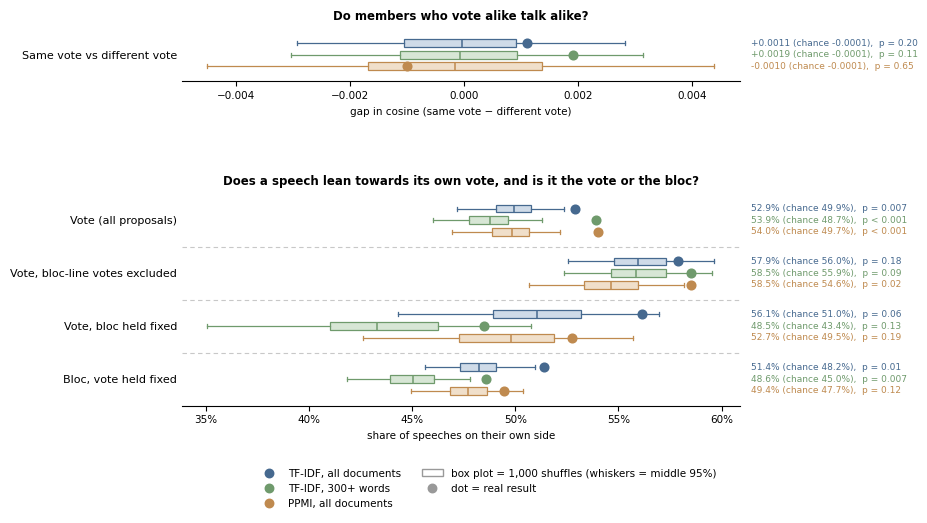

In [64]:
COL = ['#46698f', '#6f9a6c', '#bf8a4f']        # TF-IDF all, TF-IDF 300+, PPMI
TINT = ['#cfdbe8', '#d7e6d5', '#f0dfca']
NAMES = [v[0] for v in versions]

paper_panels = [
    ('Do members who vote alike talk alike?', 'gap', [
        ('Same vote vs different vote', [(res_all, null_all), (res_long, null_long), (res6_ppmi, null6_ppmi)])]),
    ('Does a speech lean towards its own vote, and is it the vote or the bloc?', 'on own side', [
        ('Vote (all proposals)', [(res7_all, null7_all), (res7_long, null7_long), (res7_ppmi, null7_ppmi)])] +
        [(t, [(r, n) for _, r, n in rows]) for t, rows in bloc_tests.items()]),
]

fig, axes = plt.subplots(2, 1, figsize=(7.2, 4.9), gridspec_kw={'height_ratios': [1, 4], 'hspace': 0.85})
for ax, (title, key, rows) in zip(axes, paper_panels):
    ys = list(range(len(rows)))[::-1]
    for y, (label, vers) in zip(ys, rows):
        for k, (res, null) in enumerate(vers):
            yy = y + 0.22 - 0.22 * k
            null = np.asarray(null)
            lo, q1, med, q3, hi = np.percentile(null, [2.5, 25, 50, 75, 97.5])
            ax.bxp([dict(whislo=lo, q1=q1, med=med, q3=q3, whishi=hi, fliers=[])], positions=[yy], widths=0.15,
                   orientation='horizontal', showfliers=False, patch_artist=True, manage_ticks=False,
                   boxprops=dict(facecolor=TINT[k], edgecolor=COL[k], lw=0.9), medianprops=dict(color=COL[k], lw=1.1),
                   whiskerprops=dict(color=COL[k], lw=0.9), capprops=dict(color=COL[k], lw=0.9), zorder=1)
            ax.scatter(res[key], yy, s=38, facecolor=COL[k], edgecolor=COL[k], linewidth=1.1, zorder=3)
            pv = res['p (vs shuffled)']
            ptx = 'p < 0.001' if pv < 0.001 else f'p = {pv:.3f}' if pv < 0.01 else f'p = {pv:.2f}'
            val = f"{res[key]:+.4f} (chance {null.mean():+.4f})" if key == 'gap' else f"{res[key]:.1%} (chance {null.mean():.1%})"
            ax.annotate(f'{val},  {ptx}', xy=(1.02, yy), xycoords=('axes fraction', 'data'), va='center', fontsize=6.5, color=COL[k])
    ax.set_yticks(ys); ax.set_yticklabels([r[0] for r in rows], fontsize=8)
    ax.tick_params(axis='y', length=0); ax.tick_params(axis='x', labelsize=7.5)
    ax.set_ylim(min(ys) - 0.5, max(ys) + 0.5)
    for y in ys[:-1]:
        ax.axhline(y - 0.5, color='#c8c8c8', lw=0.8, ls=(0, (4, 3)), zorder=0)
    ax.set_title(title, fontsize=8.5, fontweight='bold')
    if key == 'gap':
        ax.set_xlabel('gap in cosine (same vote − different vote)', fontsize=7.5)
    else:
        ax.set_xlabel('share of speeches on their own side', fontsize=7.5)
        ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
    ax.spines[['top', 'right', 'left']].set_visible(False)
h = [mlines.Line2D([], [], color=COL[k], marker='o', ls='', markerfacecolor=COL[k], markeredgecolor=COL[k],
                   markeredgewidth=1.1, markersize=6, label=NAMES[k]) for k in range(3)]
h.append(mpatches.Patch(facecolor='white', edgecolor='#999', label='box plot = 1,000 shuffles (whiskers = middle 95%)'))
h.append(mlines.Line2D([], [], color='#999', marker='o', ls='', markerfacecolor='#999', markeredgecolor='#999',
                       markeredgewidth=1.1, markersize=6, label='dot = real result'))
fig.legend(handles=h, loc='lower center', ncol=2, fontsize=7.5, frameon=False, bbox_to_anchor=(0.55, -0.12))
plt.savefig('figures_for_report/boxplot.png', dpi=250, bbox_inches='tight')
plt.show()

### 11. Niðurstøða

**Read the figures from top to bottom:**
1. **Not alike.** Members who vote the same way do not use more similar words (all three dots inside the shuffles).
2. **A small lean.** Speeches lean slightly towards their own vote (all three dots outside the shuffles).
3. **The lean is the bloc.** Without bloc-line votes the lean is gone; with the bloc held fixed it is not clear; with the vote held fixed, the bloc is clear.

**The words follow the bloc rather than the vote.**

**With all three versions (11c):** TF-IDF (all documents and 300+ words) tells the same story. PPMI is less clean: it still leans a little towards the vote when bloc-line votes are excluded (p ≈ 0.02), but not when the bloc is held fixed (p ≈ 0.19), and it does not show the bloc when the vote is held fixed (p ≈ 0.12). The cleanest test of the vote, **bloc held fixed**, is not clear in any version. With 9 tests in this group, one p ≈ 0.02 can also be luck (multiple comparisons).

## Step 12: check without Kristin Michelsen

Kristin Michelsen (Sjálvstýri) is formally in the **opposition**, but in the voting network (Fig. 1 in the paper) he votes with the **government**. So the bloc label may be wrong for him, and that could change the bloc tests.

Here every test from Step 11 is run again **without his documents**. Everything else is the same: the same TF-IDF and PPMI vectors, 1,000 shuffles, seed 1. Bloc-line votes are decided again without him, since his vote can break a bloc line.

In [65]:
km = (fi['name'] == 'Kristin Michelsen').to_numpy()
not_km = ~km
print(f"Kristin Michelsen: {km.sum()} of {len(fi):,} documents, on {fi.loc[km, 'case_number'].nunique()} cases "
      f"(Fyri {(fi.loc[km, 'vote'] == 'Fyri').sum()}, Ímóti {(fi.loc[km, 'vote'] == 'Ímóti').sum()})")

# bloc-line votes, decided again without him (as in 8b)
pure_x_km = set()
for case, pos in fi[not_km].groupby('case_number').indices.items():
    rows_ = fi[not_km].index[pos]
    F, Gv = vote_arr[rows_] == 'Fyri', bloc_arr[rows_] == 'government'
    if (F == Gv).all() or (F == ~Gv).all():
        pure_x_km.add(case)
no_x_km = ~fi['case_number'].isin(pure_x_km).to_numpy()

versions_km = [('TF-IDF, all documents', X, all_rows), ('TF-IDF, 300+ words', X, long_rows), ('PPMI, all documents', D, all_rows)]
with_him = {
    'Alike (gap)':                    [res_all, res_long, res6_ppmi],
    'Own vote':                       [res7_all, res7_long, res7_ppmi],
    'Vote, bloc-line votes excluded': [r for _, r, _ in bloc_tests['Vote, bloc-line votes excluded']],
    'Vote, bloc held fixed':          [r for _, r, _ in bloc_tests['Vote, bloc held fixed']],
    'Bloc, vote held fixed':          [r for _, r, _ in bloc_tests['Bloc, vote held fixed']],
}
without_him = {t: [] for t in with_him}
for vname, Dm, keep in versions_km:
    k = keep & not_km
    without_him['Alike (gap)'].append(gap_test(Dm, k)[0])
    without_him['Own vote'].append(arrow_test(Dm, k)[0])
    without_him['Vote, bloc-line votes excluded'].append(arrow_test(Dm, no_x_km & k)[0])
    without_him['Vote, bloc held fixed'].append(arrow_test_by_version('vote', 'Fyri', ['case_number', 'bloc'], Dm, k)[0])
    without_him['Bloc, vote held fixed'].append(arrow_test_by_version('bloc', 'government', ['case_number', 'vote'], Dm, k)[0])

def result_text(res):
    return f"{res['gap']:+.4f}" if 'gap' in res else f"{res['on own side']:.1%}"

step12 = pd.DataFrame([{'test': t, 'version': v,
                        'with him': result_text(a), 'p with him': a['p (vs shuffled)'],
                        'without him': result_text(b), 'p without him': b['p (vs shuffled)']}
                       for t in with_him
                       for (v, _, _), a, b in zip(versions_km, with_him[t], without_him[t])])
step12.style.hide(axis='index').format({'p with him': '{:.3f}', 'p without him': '{:.3f}'})

Kristin Michelsen: 9 of 3,091 documents, on 9 cases (Fyri 7, Ímóti 2)


test,version,with him,p with him,without him,p without him
Alike (gap),"TF-IDF, all documents",+0.0011,0.205,+0.0011,0.215
Alike (gap),"TF-IDF, 300+ words",+0.0019,0.112,+0.0019,0.123
Alike (gap),"PPMI, all documents",-0.0010,0.649,-0.0009,0.641
Own vote,"TF-IDF, all documents",52.9%,0.007,52.8%,0.017
Own vote,"TF-IDF, 300+ words",53.9%,0.000,53.8%,0.000
Own vote,"PPMI, all documents",54.0%,0.000,53.9%,0.000
"Vote, bloc-line votes excluded","TF-IDF, all documents",57.9%,0.181,57.8%,0.202
"Vote, bloc-line votes excluded","TF-IDF, 300+ words",58.5%,0.090,58.7%,0.101
"Vote, bloc-line votes excluded","PPMI, all documents",58.5%,0.018,58.4%,0.040
"Vote, bloc held fixed","TF-IDF, all documents",56.1%,0.058,56.5%,0.058


### 12. Niðurstøða

**Kristin Michelsen does not change the results.** He has only 9 of the 3,091 documents. Without him, every number moves only a little (about one percentage point at most), and every test gives the same answer as before:
- Members who vote alike still do not talk more alike (all p > 0.1).
- Speeches still lean towards their own vote (TF-IDF, all documents: p = 0.017 instead of 0.007).
- With the bloc held fixed, the lean is still not clear; with the vote held fixed, the bloc still shows with TF-IDF.

So the sentence in the paper holds: leaving him out gives the same conclusions.